In [161]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [162]:
df = pd.read_csv('kicksharing.csv')
df

,order_rk,party_rk,gender_cd,age,education_level_cd,marital_status_cd,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,created_dttm,book_start_dttm,book_end_dttm,book_time_zone_cd,local_book_start_dttm,nominal_price_rub_amt,loyalty_accrual_rub_amt,loyalty_accrual_bns_amt
0,266071307,761067705,M,40,UGR,DIV,ТЮМЕНСКАЯ ОБЛ,4.99,30.0,300.0,SL,3.690479,2024-08-07 09:47:25.000000,2024-08-07 09:47:29.325252,2024-08-07 10:07:59.339524,5,2024-08-07 11:47:29.325252,134.79,19.48,NaN
1,355113920,614049469,F,30,GRD,MAR,РОСТОВСКАЯ ОБЛ,8.49,50.0,300.0,SL,1.114912,2024-10-17 14:57:20.000000,2024-10-17 14:57:24.586000,2024-10-17 15:04:19.419607,3,2024-10-17 14:57:24.586000,109.43,40.30,NaN
2,347424551,757583701,M,28,UGR,UNM,СВЕРДЛОВСКАЯ ОБЛ,5.99,30.0,300.0,E,1.515612,2024-09-19 05:31:41.000000,2024-09-19 05:34:59.476000,2024-09-19 05:41:50.164372,5,2024-09-19 07:34:59.476000,71.93,10.79,NaN
3,351562959,541367366,M,24,GRD,UNM,Г МОСКВА,8.99,50.0,300.0,SL,0.499411,2024-10-04 16:05:09.000000,2024-10-04 16:05:13.162000,2024-10-04 16:07:31.724918,3,2024-10-04 16:05:13.162000,76.97,7.70,NaN
4,258647149,238473615,M,34,NaN,NaN,Г МОСКВА,6.99,50.0,300.0,SL,2.602028,2024-07-10 06:57:40.000000,2024-07-10 06:57:43.017125,2024-07-10 07:07:48.446462,3,2024-07-10 06:57:43.017125,126.89,25.38,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396744,349109813,755778419,M,18,NaN,NaN,СВЕРДЛОВСКАЯ ОБЛ,6.49,30.0,300.0,E,1.555069,2024-09-25 11:39:42.000000,2024-09-25 11:39:46.885000,2024-09-25 11:45:41.545313,5,2024-09-25 13:39:46.885000,68.94,6.89,NaN
396745,348829245,1146263947,M,23,NaN,NaN,КАЛИНИНГРАДСКАЯ ОБЛ,8.99,30.0,300.0,Max,2.270902,2024-09-24 20:05:43.000000,2024-09-24 20:05:46.954000,2024-09-24 20:13:58.592279,2,2024-09-24 19:05:46.954000,110.91,13.09,NaN
396746,273529251,1012601147,M,20,NaN,NaN,ТЮМЕНСКАЯ ОБЛ,8.79,50.0,300.0,E,1.411171,2024-09-03 16:07:43.000000,2024-09-03 16:07:45.311487,2024-09-03 16:28:07.510118,3,2024-09-03 16:07:45.311487,234.59,234.59,NaN
396747,306062051,863877659,M,19,NaN,NaN,Г САНКТ-ПЕТЕРБУРГ,7.49,50.0,300.0,SL,1.002400,2024-09-12 18:28:48.000000,2024-09-12 18:28:50.401000,2024-09-12 18:32:22.911827,3,2024-09-12 18:28:50.401000,79.96,79.96,NaN


In [163]:
df.shape

(396749, 20)

In [164]:
df.columns

Index(['order_rk', 'party_rk', 'gender_cd', 'age', 'education_level_cd',
       'marital_status_cd', 'lvn_state_nm', 'minute_cost', 'activation_cost',
       'hold_amount', 'transport_model', 'distance_km', 'created_dttm',
       'book_start_dttm', 'book_end_dttm', 'book_time_zone_cd',
       'local_book_start_dttm', 'nominal_price_rub_amt',
       'loyalty_accrual_rub_amt', 'loyalty_accrual_bns_amt'],
      dtype='object')

In [165]:
df.head()

,order_rk,party_rk,gender_cd,age,education_level_cd,marital_status_cd,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,created_dttm,book_start_dttm,book_end_dttm,book_time_zone_cd,local_book_start_dttm,nominal_price_rub_amt,loyalty_accrual_rub_amt,loyalty_accrual_bns_amt
0,266071307,761067705,M,40,UGR,DIV,ТЮМЕНСКАЯ ОБЛ,4.99,30.0,300.0,SL,3.690479,2024-08-07 09:47:25.000000,2024-08-07 09:47:29.325252,2024-08-07 10:07:59.339524,5,2024-08-07 11:47:29.325252,134.79,19.48,NaN
1,355113920,614049469,F,30,GRD,MAR,РОСТОВСКАЯ ОБЛ,8.49,50.0,300.0,SL,1.114912,2024-10-17 14:57:20.000000,2024-10-17 14:57:24.586000,2024-10-17 15:04:19.419607,3,2024-10-17 14:57:24.586000,109.43,40.30,NaN
2,347424551,757583701,M,28,UGR,UNM,СВЕРДЛОВСКАЯ ОБЛ,5.99,30.0,300.0,E,1.515612,2024-09-19 05:31:41.000000,2024-09-19 05:34:59.476000,2024-09-19 05:41:50.164372,5,2024-09-19 07:34:59.476000,71.93,10.79,NaN
3,351562959,541367366,M,24,GRD,UNM,Г МОСКВА,8.99,50.0,300.0,SL,0.499411,2024-10-04 16:05:09.000000,2024-10-04 16:05:13.162000,2024-10-04 16:07:31.724918,3,2024-10-04 16:05:13.162000,76.97,7.70,NaN
4,258647149,238473615,M,34,NaN,NaN,Г МОСКВА,6.99,50.0,300.0,SL,2.602028,2024-07-10 06:57:40.000000,2024-07-10 06:57:43.017125,2024-07-10 07:07:48.446462,3,2024-07-10 06:57:43.017125,126.89,25.38,NaN


In [166]:
df.duplicated().sum()

np.int64(0)

In [167]:
df.duplicated(subset=["order_rk"]).sum()

np.int64(0)

Дубликатов нет

In [168]:
df.isna().sum()

,0
order_rk,0
party_rk,0
gender_cd,2921
age,0
education_level_cd,206690
marital_status_cd,179020
lvn_state_nm,34177
minute_cost,0
activation_cost,0
hold_amount,0


пропуски в числовых признаках только в признаках про размер выплаченного кэшбэка. в нечисловых много где

вообще похоже, что датасет появился как объединение логов поездок и банковских клиентских данных, судя по признакам. там есть и лояльность, и данные клиента, и все на свете. оттого и пропусков много в том же уровне образования, например. мерджили по айдишнику клиента видимо

In [169]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396749 entries, 0 to 396748
Data columns (total 20 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   order_rk                 396749 non-null  int64  
 1   party_rk                 396749 non-null  int64  
 2   gender_cd                393828 non-null  object 
 3   age                      396749 non-null  int64  
 4   education_level_cd       190059 non-null  object 
 5   marital_status_cd        217729 non-null  object 
 6   lvn_state_nm             362572 non-null  object 
 7   minute_cost              396749 non-null  float64
 8   activation_cost          396749 non-null  float64
 9   hold_amount              396749 non-null  float64
 10  transport_model          396749 non-null  object 
 11  distance_km              396749 non-null  float64
 12  created_dttm             396749 non-null  object 
 13  book_start_dttm          396749 non-null  object 
 14  book

бомба, нет числовых в типе object. то что айдишники числовые норм

In [170]:
df.describe()

,order_rk,party_rk,age,minute_cost,activation_cost,hold_amount,distance_km,book_time_zone_cd,nominal_price_rub_amt,loyalty_accrual_rub_amt,loyalty_accrual_bns_amt
count,3.967490e+05,3.967490e+05,396749.000000,396749.000000,396749.000000,396749.000000,396749.000000,396749.000000,396749.000000,366992.000000,21948.000000
mean,2.892236e+08,5.988426e+08,31.544006,7.288688,42.593226,299.983869,3.681031,3.536155,127.647694,37.516121,127.789319
std,3.813458e+07,3.311675e+08,9.434545,1.289492,11.989974,1.939153,141.862349,1.209075,100.122365,75.208560,496.812143
min,2.526112e+08,1.471700e+04,12.000000,1.500000,0.000000,80.000000,0.000000,0.000000,0.000000,-161.940000,1.000000
25%,2.618150e+08,2.962323e+08,24.000000,6.490000,30.000000,300.000000,0.941054,3.000000,80.840000,11.240000,43.000000
50%,2.704367e+08,6.110092e+08,31.000000,7.490000,50.000000,300.000000,1.729883,3.000000,103.940000,18.730000,62.000000
75%,3.432678e+08,8.646921e+08,37.000000,8.220000,50.000000,300.000000,3.063694,3.000000,142.100000,35.060000,81.000000
max,3.562528e+08,1.301075e+09,94.000000,19.990000,50.000000,500.000000,56012.640308,12.000000,5627.640000,3185.000000,55429.360970


тут естественно не смотрим на айдишники клиента и поездки - они просто числовые и норм

# Работа с пропусками

In [171]:
print('% gender_cd :', df['gender_cd'].isna().mean() * 100)
print('% education_level_cd :', df['education_level_cd'].isna().mean() * 100)
print('% marital_status_cd :', df['marital_status_cd'].isna().mean() * 100)
print('% lvn_state_nm :', df['lvn_state_nm'].isna().mean() * 100)
print('% loyalty_accrual_rub_amt :', df['loyalty_accrual_rub_amt'].isna().mean() * 100)
print('% loyalty_accrual_bns_amt :', df['loyalty_accrual_bns_amt'].isna().mean() * 100)

% gender_cd : 0.7362337397195707
% education_level_cd : 52.095909504497804
% marital_status_cd : 45.12172683485024
% lvn_state_nm : 8.614262417800674
% loyalty_accrual_rub_amt : 7.500207940032615
% loyalty_accrual_bns_amt : 94.46803898686575


дропаем loyalty_accrual_bns_amt, education_level_cd и marital_status_cd

In [172]:
df = df.drop(columns=["loyalty_accrual_bns_amt", "marital_status_cd", "education_level_cd"])

In [173]:
df.columns

Index(['order_rk', 'party_rk', 'gender_cd', 'age', 'lvn_state_nm',
       'minute_cost', 'activation_cost', 'hold_amount', 'transport_model',
       'distance_km', 'created_dttm', 'book_start_dttm', 'book_end_dttm',
       'book_time_zone_cd', 'local_book_start_dttm', 'nominal_price_rub_amt',
       'loyalty_accrual_rub_amt'],
      dtype='object')

нечисловые заполним модой

In [174]:
print(df["gender_cd"].mode()[0])
print(df["lvn_state_nm"].mode()[0])

M
Г МОСКВА


In [175]:
df["gender_cd"] = df["gender_cd"].fillna(df["gender_cd"].mode()[0])
df["lvn_state_nm"] = df["lvn_state_nm"].fillna(df["lvn_state_nm"].mode()[0])

смотрим много ли выбросов в loyalty_accrual_rub_amt

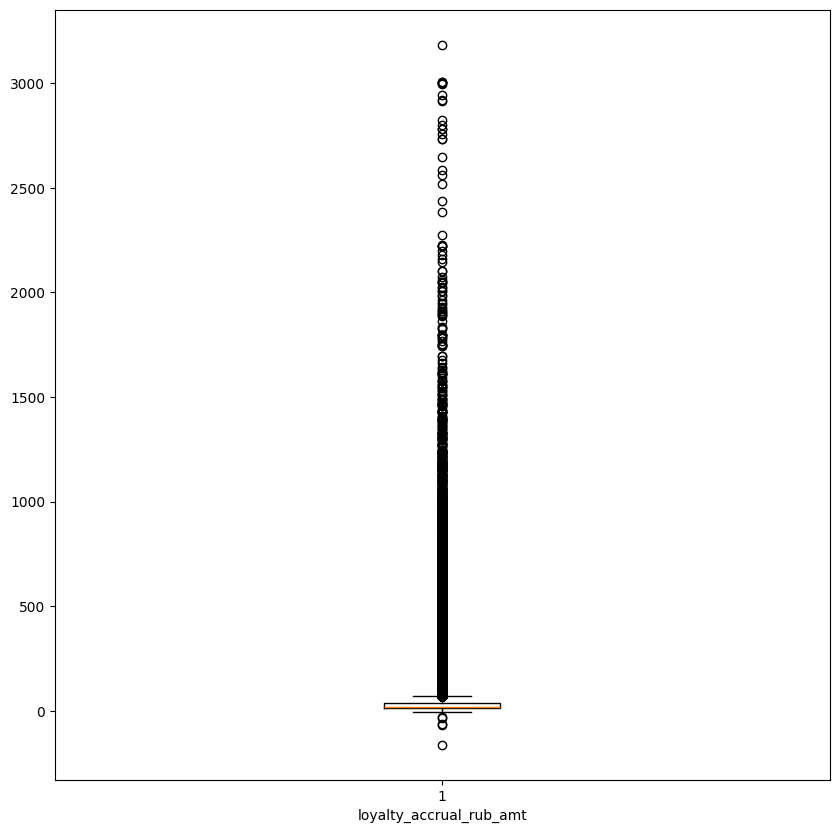

In [176]:
plt.figure(figsize=(10, 10))
plt.boxplot(df["loyalty_accrual_rub_amt"].dropna())

plt.xlabel("loyalty_accrual_rub_amt")
plt.show()

кстати заметим что есть отрицательные значения!!!

In [177]:
df[df["loyalty_accrual_rub_amt"] <= 0]

,order_rk,party_rk,gender_cd,age,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,created_dttm,book_start_dttm,book_end_dttm,book_time_zone_cd,local_book_start_dttm,nominal_price_rub_amt,loyalty_accrual_rub_amt
133193,346866316,520065368,F,38,Г САНКТ-ПЕТЕРБУРГ,7.99,50.0,300.0,SL,2.962408,2024-09-17 19:21:36.000000,2024-09-17 19:21:40.574000,2024-09-17 20:50:58.414000,3,2024-09-17 19:21:40.574000,769.10,-33.52
218430,350556979,1068354351,F,77,СВЕРДЛОВСКАЯ ОБЛ,6.49,30.0,300.0,E,0.287968,2024-09-30 13:18:30.000000,2024-09-30 13:18:34.985000,2024-09-30 13:58:37.830000,5,2024-09-30 15:18:34.985000,296.09,-67.83
225743,263337728,544337483,M,22,Г МОСКВА,8.86,50.0,300.0,SL,13.229882,2024-07-28 15:43:29.000000,2024-07-28 15:43:31.515713,2024-07-28 16:10:19.203000,3,2024-07-28 15:43:31.515713,289.22,-8.08
272310,348557969,904357431,M,18,КРАСНОЯРСКИЙ КРАЙ,6.49,0.0,300.0,SL,3.125962,2024-09-23 15:15:20.000000,2024-09-23 15:15:26.060000,2024-09-23 16:07:48.379234,7,2024-09-23 19:15:26.060000,343.97,-65.29
297741,266324787,952764064,M,46,МОСКОВСКАЯ ОБЛ,6.99,50.0,300.0,SL,29.264670,2024-08-08 13:28:06.000000,2024-08-08 13:28:10.899262,2024-08-08 16:52:01.011173,3,2024-08-08 13:28:10.899262,1475.96,-30.62
299220,351047641,759332373,M,27,Г САНКТ-ПЕТЕРБУРГ,7.99,50.0,300.0,SL,0.467784,2024-10-01 22:19:00.000000,2024-10-01 22:19:05.461000,2024-10-01 22:22:58.094771,3,2024-10-01 22:19:05.461000,81.96,-5.00
340555,261319091,943073656,M,30,Г МОСКВА,8.39,50.0,300.0,SL,12.620194,2024-07-20 13:36:12.000000,2024-07-20 13:36:16.909581,2024-07-20 17:11:41.426445,3,2024-07-20 13:36:16.909581,1862.24,-161.94


а тут дошло, что пропуск это просто кэшбэк не начислялся!!! поэтому заполняем нулями.

In [178]:
df["loyalty_accrual_rub_amt"] = df["loyalty_accrual_rub_amt"].fillna(0)

In [179]:
df.isna().sum()

,0
order_rk,0
party_rk,0
gender_cd,0
age,0
lvn_state_nm,0
minute_cost,0
activation_cost,0
hold_amount,0
transport_model,0
distance_km,0


на всякий еще посмотрим значения в признаках и на этом все

In [180]:
df["transport_model"].value_counts()

,count
transport_model,
SL,241247
Max,70301
E,67666
Urban E-Bike,4704
ES400,4152
ES200,3325
ES100,2829
MK,1054
ES-08S,911


In [181]:
df["book_time_zone_cd"].value_counts()

,count
book_time_zone_cd,
3,300180
5,50804
7,18174
4,15036
2,7107
8,3714
10,911
9,341
11,296


In [182]:
df["hold_amount"].value_counts()

,count
hold_amount,
300.0,396718
80.0,30
500.0,1


In [183]:
df[df["hold_amount"] != 300][["hold_amount", "transport_model", "lvn_state_nm", "created_dttm", "nominal_price_rub_amt"]]

,hold_amount,transport_model,lvn_state_nm,created_dttm,nominal_price_rub_amt
16038,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-08-09 19:41:55.000000,78.50
18608,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-08-14 19:54:56.000000,425.00
23277,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-10-08 04:37:24.000000,51.00
44836,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-08-10 18:19:30.000000,0.00
69424,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-09-16 09:12:17.000000,6.50
89813,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-08-14 15:32:04.000000,47.00
103720,80.0,Lucky,ЧЕЛЯБИНСКАЯ ОБЛ,2024-09-10 11:02:18.000000,47.00
142392,80.0,Lucky,КРАСНОДАРСКИЙ КРАЙ,2024-08-19 07:35:24.000000,11.00
150392,500.0,ES100,Г МОСКВА,2024-06-25 14:00:23.000000,62.45
170831,80.0,Lucky,РОСТОВСКАЯ ОБЛ,2024-08-29 16:10:10.000000,63.00


In [184]:
df[df['transport_model'] == 'Lucky']

,order_rk,party_rk,gender_cd,age,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,created_dttm,book_start_dttm,book_end_dttm,book_time_zone_cd,local_book_start_dttm,nominal_price_rub_amt,loyalty_accrual_rub_amt
16038,266602218,791320911,M,34,КРАСНОДАРСКИЙ КРАЙ,1.5,5.0,80.0,Lucky,0.000000,2024-08-09 19:41:55.000000,2024-08-09 19:41:58.426053,2024-08-09 20:30:41.418000,3,2024-08-09 19:41:58.426053,78.5,23.55
17400,274147824,819492789,M,18,РЕСП БАШКОРТОСТАН,2.0,0.0,300.0,Lucky,0.000000,2024-09-05 14:14:46.000000,2024-09-05 14:14:48.978652,2024-09-05 14:15:18.516407,5,2024-09-05 16:14:48.978652,0.0,0.00
18350,350277704,771579225,M,35,Г МОСКВА,2.5,0.0,300.0,Lucky,0.000000,2024-09-29 16:44:08.000000,2024-09-29 16:44:12.121000,2024-09-29 16:45:05.966562,3,2024-09-29 16:44:12.121000,0.0,0.00
18608,267910412,1169868540,M,23,КРАСНОДАРСКИЙ КРАЙ,1.5,5.0,80.0,Lucky,0.234842,2024-08-14 19:54:56.000000,2024-08-14 19:55:00.692540,2024-08-15 00:35:01.877000,3,2024-08-14 19:55:00.692540,425.0,63.50
22526,347723225,1009974722,F,70,Г МОСКВА,2.0,0.0,300.0,Lucky,0.000000,2024-09-20 15:22:46.000000,2024-09-20 15:22:55.429000,2024-09-20 15:33:40.560373,5,2024-09-20 17:22:55.429000,22.0,22.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355941,273259408,136737629,M,39,РЯЗАНСКАЯ ОБЛ,2.5,0.0,300.0,Lucky,0.000000,2024-09-02 14:41:46.000000,2024-09-02 14:41:50.786903,2024-09-02 14:44:54.065622,3,2024-09-02 14:41:50.786903,7.5,2.25
365733,343265975,169217890,M,28,РЕСП БАШКОРТОСТАН,2.0,0.0,300.0,Lucky,0.000000,2024-09-16 17:22:29.000000,2024-09-16 17:22:32.821000,2024-09-16 17:26:33.614408,5,2024-09-16 19:22:32.821000,8.0,0.80
372137,314896820,130848107,M,41,КРАСНОДАРСКИЙ КРАЙ,4.0,35.0,80.0,Lucky,0.000000,2024-09-13 17:39:24.000000,2024-09-13 17:39:28.270000,2024-09-13 17:42:29.369441,3,2024-09-13 17:39:28.270000,47.0,47.00
390842,267912736,111470999,M,35,КРАСНОЯРСКИЙ КРАЙ,4.0,35.0,80.0,Lucky,0.000000,2024-08-14 08:24:46.000000,2024-08-14 08:24:50.771647,2024-08-14 08:32:12.505869,3,2024-08-14 08:24:50.771647,67.0,0.00


это все из-за того, что лаки - это тоже кикшеринговый сервис, который был выкуплен юрентом. возможно, удержание 80руб было в какой-то период из-за акции или другой причины, может из-за поглощения и вследствие скидок. при этом заметим, что в целом у лаки очень много коротких поездок которые почти не начинались, а километраж на них был вообще околонулевой - могла плохо писаться телеметрия дистанции.

500р - может быть все что угодно (сбой системы, может это вообще тестировщик забыл данные почистить).

In [185]:
df["gender_cd"].value_counts()

,count
gender_cd,
M,338379
F,58370


In [186]:
df["age"].value_counts()

,count
age,
25,17366
24,16904
22,16718
33,16326
23,15874
...,...
85,5
12,1
86,1


In [187]:
df["lvn_state_nm"].value_counts()

,count
lvn_state_nm,
Г МОСКВА,125074
МОСКОВСКАЯ ОБЛ,40440
Г САНКТ-ПЕТЕРБУРГ,36867
СВЕРДЛОВСКАЯ ОБЛ,28952
КРАСНОДАРСКИЙ КРАЙ,16533
...,...
ЧУВАШИЯ ЧУВАШСКАЯ РЕСПУБЛИКА -,1
ИРКУТСКАЯ ОБЛАСТЬ,1
ОБЛАСТЬ УЛЬЯНОВСКАЯ,1


ага попался !! тут чет не то в месте проживания. тут должен быть только регион проживания. все нормализуем

In [188]:
print(df["lvn_state_nm"].value_counts().to_string())

lvn_state_nm
Г МОСКВА                                       125074
МОСКОВСКАЯ ОБЛ                                  40440
Г САНКТ-ПЕТЕРБУРГ                               36867
СВЕРДЛОВСКАЯ ОБЛ                                28952
КРАСНОДАРСКИЙ КРАЙ                              16533
РЕСП ТАТАРСТАН                                   9499
РЕСП БАШКОРТОСТАН                                8377
НИЖЕГОРОДСКАЯ ОБЛ                                7758
НОВОСИБИРСКАЯ ОБЛ                                7158
КРАСНОЯРСКИЙ КРАЙ                                5671
РОСТОВСКАЯ ОБЛ                                   5637
РЕСП УДМУРТСКАЯ                                  5564
ЛЕНИНГРАДСКАЯ ОБЛ                                5519
ТЮМЕНСКАЯ ОБЛ                                    5222
САМАРСКАЯ ОБЛ                                    5085
КАЛИНИНГРАДСКАЯ ОБЛ                              4585
САРАТОВСКАЯ ОБЛ                                  4507
ЧЕЛЯБИНСКАЯ ОБЛ                                  4379
ИРКУТСКАЯ ОБЛ  

In [189]:
df["lvn_state_nm_clean"] = df["lvn_state_nm"]
df["lvn_state_nm_clean"] = df["lvn_state_nm_clean"].str.replace("Ё", "Е")
df["lvn_state_nm_clean"] = df["lvn_state_nm_clean"].str.replace(".", "")
df["lvn_state_nm_clean"] = df["lvn_state_nm_clean"].str.replace(r"\s+", " ", regex=True)

region_map = {
    "Г МОСКВА": "МОСКВА",
    "ГОРОД МОСКВА": "МОСКВА",
    "МОСКВА Г": "МОСКВА",
    "МОСККОВСКАЯ": "МОСКОВСКАЯ ОБЛАСТЬ",
    "МОСКОВСКАЯ": "МОСКОВСКАЯ ОБЛАСТЬ",
    "МОСКОВСКАЯ ОБЛ": "МОСКОВСКАЯ ОБЛАСТЬ",
    "ОБЛ МОСКОВСКАЯ": "МОСКОВСКАЯ ОБЛАСТЬ",
    "ОБЛ МОСКОВСКАЯ": "МОСКОВСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ МОСКОВСКАЯ": "МОСКОВСКАЯ ОБЛАСТЬ",

    "Г САНКТ-ПЕТЕРБУРГ": "САНКТ-ПЕТЕРБУРГ",
    "ГОРОД САНКТ-ПЕТЕРБУРГ": "САНКТ-ПЕТЕРБУРГ",
    "САНКТ-ПЕТЕРБУРГ Г": "САНКТ-ПЕТЕРБУРГ",

    "Г СЕВАСТОПОЛЬ": "СЕВАСТОПОЛЬ",

    "СВЕРДЛОВСКАЯ ОБЛ": "СВЕРДЛОВСКАЯ ОБЛАСТЬ",
    "ОБЛ СВЕРДЛОВСКАЯ": "СВЕРДЛОВСКАЯ ОБЛАСТЬ",
    "ОБЛ СВЕРДЛОВСКАЯ": "СВЕРДЛОВСКАЯ ОБЛАСТЬ",
    "СВЕРДЛОВСКАЯ": "СВЕРДЛОВСКАЯ ОБЛАСТЬ",

    "НИЖЕГОРОДСКАЯ ОБЛ": "НИЖЕГОРОДСКАЯ ОБЛАСТЬ",
    "ОБЛ НИЖЕГОРОДСКАЯ": "НИЖЕГОРОДСКАЯ ОБЛАСТЬ",
    "НИЖЕГОРОДСКАЯ": "НИЖЕГОРОДСКАЯ ОБЛАСТЬ",

    "НОВОСИБИРСКАЯ ОБЛ": "НОВОСИБИРСКАЯ ОБЛАСТЬ",
    "ОБЛ НОВОСИБИРСКАЯ": "НОВОСИБИРСКАЯ ОБЛАСТЬ",
    "НОВОСИБИРСКАЯ": "НОВОСИБИРСКАЯ ОБЛАСТЬ",

    "РОСТОВСКАЯ ОБЛ": "РОСТОВСКАЯ ОБЛАСТЬ",
    "ОБЛ РОСТОВСКАЯ": "РОСТОВСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ РОСТОВСКАЯ": "РОСТОВСКАЯ ОБЛАСТЬ",

    "ЛЕНИНГРАДСКАЯ ОБЛ": "ЛЕНИНГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛ ЛЕНИНГРАДСКАЯ": "ЛЕНИНГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛ ЛЕНИНГРАДСКАЯ": "ЛЕНИНГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ ЛЕНИНГРАДСКАЯ": "ЛЕНИНГРАДСКАЯ ОБЛАСТЬ",
    "ЛЕНЕНГРАДСКАЯ ОБЛ": "ЛЕНИНГРАДСКАЯ ОБЛАСТЬ",

    "САМАРСКАЯ ОБЛ": "САМАРСКАЯ ОБЛАСТЬ",
    "ОБЛ САМАРСКАЯ": "САМАРСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ САМАРСКАЯ": "САМАРСКАЯ ОБЛАСТЬ",
    "Г САМАРА": "САМАРСКАЯ ОБЛАСТЬ",

    "КАЛИНИНГРАДСКАЯ ОБЛ": "КАЛИНИНГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛ КАЛИНИНГРАДСКАЯ": "КАЛИНИНГРАДСКАЯ ОБЛАСТЬ",

    "САРАТОВСКАЯ ОБЛ": "САРАТОВСКАЯ ОБЛАСТЬ",
    "ОБЛ САРАТОВСКАЯ": "САРАТОВСКАЯ ОБЛАСТЬ",

    "ЧЕЛЯБИНСКАЯ ОБЛ": "ЧЕЛЯБИНСКАЯ ОБЛАСТЬ",
    "ОБЛ ЧЕЛЯБИНСКАЯ": "ЧЕЛЯБИНСКАЯ ОБЛАСТЬ",

    "ИРКУТСКАЯ ОБЛ": "ИРКУТСКАЯ ОБЛАСТЬ",
    "ОБЛ ИРКУТСКАЯ": "ИРКУТСКАЯ ОБЛАСТЬ",

    "ВОЛГОГРАДСКАЯ ОБЛ": "ВОЛГОГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛ ВОЛГОГРАДСКАЯ": "ВОЛГОГРАДСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ ВОЛГОГРАДСКАЯ": "ВОЛГОГРАДСКАЯ ОБЛАСТЬ",

    "ТОМСКАЯ ОБЛ": "ТОМСКАЯ ОБЛАСТЬ",
    "ОБЛ ТОМСКАЯ": "ТОМСКАЯ ОБЛАСТЬ",

    "ВОРОНЕЖСКАЯ ОБЛ": "ВОРОНЕЖСКАЯ ОБЛАСТЬ",
    "ОБЛ ВОРОНЕЖСКАЯ": "ВОРОНЕЖСКАЯ ОБЛАСТЬ",

    "КИРОВСКАЯ ОБЛ": "КИРОВСКАЯ ОБЛАСТЬ",
    "ОБЛ КИРОВСКАЯ": "КИРОВСКАЯ ОБЛАСТЬ",

    "ЯРОСЛАВСКАЯ ОБЛ": "ЯРОСЛАВСКАЯ ОБЛАСТЬ",
    "ОБЛ ЯРОСЛАВСКАЯ": "ЯРОСЛАВСКАЯ ОБЛАСТЬ",

    "ТВЕРСКАЯ ОБЛ": "ТВЕРСКАЯ ОБЛАСТЬ",
    "ОБЛ ТВЕРСКАЯ": "ТВЕРСКАЯ ОБЛАСТЬ",

    "ВОЛОГОДСКАЯ ОБЛ": "ВОЛОГОДСКАЯ ОБЛАСТЬ",
    "ОБЛ ВОЛОГОДСКАЯ": "ВОЛОГОДСКАЯ ОБЛАСТЬ",

    "РЯЗАНСКАЯ ОБЛ": "РЯЗАНСКАЯ ОБЛАСТЬ",
    "ОБЛ РЯЗАНСКАЯ": "РЯЗАНСКАЯ ОБЛАСТЬ",

    "УЛЬЯНОВСКАЯ ОБЛ": "УЛЬЯНОВСКАЯ ОБЛАСТЬ",
    "ОБЛ УЛЬЯНОВСКАЯ": "УЛЬЯНОВСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ УЛЬЯНОВСКАЯ": "УЛЬЯНОВСКАЯ ОБЛАСТЬ",

    "АСТРАХАНСКАЯ ОБЛ": "АСТРАХАНСКАЯ ОБЛАСТЬ",
    "ОБЛ АСТРАХАНСКАЯ": "АСТРАХАНСКАЯ ОБЛАСТЬ",

    "ПСКОВСКАЯ ОБЛ": "ПСКОВСКАЯ ОБЛАСТЬ",
    "ОБЛ ПСКОВСКАЯ": "ПСКОВСКАЯ ОБЛАСТЬ",

    "ОМСКАЯ ОБЛ": "ОМСКАЯ ОБЛАСТЬ",
    "БРЯНСКАЯ ОБЛ": "БРЯНСКАЯ ОБЛАСТЬ",
    "БЕЛГОРОДСКАЯ ОБЛ": "БЕЛГОРОДСКАЯ ОБЛАСТЬ",
    "ОБЛ БЕЛГОРОДСКАЯ": "БЕЛГОРОДСКАЯ ОБЛАСТЬ",
    "НОВГОРОДСКАЯ ОБЛ": "НОВГОРОДСКАЯ ОБЛАСТЬ",
    "ОБЛ НОВГОРОДСКАЯ": "НОВГОРОДСКАЯ ОБЛАСТЬ",
    "ОРЕНБУРГСКАЯ ОБЛ": "ОРЕНБУРГСКАЯ ОБЛАСТЬ",
    "ОБЛ ОРЕНБУРГСКАЯ": "ОРЕНБУРГСКАЯ ОБЛАСТЬ",
    "ТУЛЬСКАЯ ОБЛ": "ТУЛЬСКАЯ ОБЛАСТЬ",
    "ТАМБОВСКАЯ ОБЛ": "ТАМБОВСКАЯ ОБЛАСТЬ",
    "ОБЛ ТАМБОВСКАЯ": "ТАМБОВСКАЯ ОБЛАСТЬ",
    "КАЛУЖСКАЯ ОБЛ": "КАЛУЖСКАЯ ОБЛАСТЬ",
    "ОБЛ КАЛУЖСКАЯ": "КАЛУЖСКАЯ ОБЛАСТЬ",
    "АРХАНГЕЛЬСКАЯ ОБЛ": "АРХАНГЕЛЬСКАЯ ОБЛАСТЬ",
    "ОБЛ АРХАНГЕЛЬСКАЯ": "АРХАНГЕЛЬСКАЯ ОБЛАСТЬ",
    "ОБЛ АРХАНГЕЛЬСКАЯ": "АРХАНГЕЛЬСКАЯ ОБЛАСТЬ",
    "КУРГАНСКАЯ ОБЛ": "КУРГАНСКАЯ ОБЛАСТЬ",
    "ОБЛ КУРГАНСКАЯ": "КУРГАНСКАЯ ОБЛАСТЬ",
    "СМОЛЕНСКАЯ ОБЛ": "СМОЛЕНСКАЯ ОБЛАСТЬ",
    "ОБЛ СМОЛЕНСКАЯ": "СМОЛЕНСКАЯ ОБЛАСТЬ",
    "ПЕНЗЕНСКАЯ ОБЛ": "ПЕНЗЕНСКАЯ ОБЛАСТЬ",
    "ОБЛ ПЕНЗЕНСКАЯ": "ПЕНЗЕНСКАЯ ОБЛАСТЬ",
    "ОРЛОВСКАЯ ОБЛ": "ОРЛОВСКАЯ ОБЛАСТЬ",
    "ОБЛ ОРЛОВСКАЯ": "ОРЛОВСКАЯ ОБЛАСТЬ",
    "МУРМАНСКАЯ ОБЛ": "МУРМАНСКАЯ ОБЛАСТЬ",
    "ОБЛ МУРМАНСКАЯ": "МУРМАНСКАЯ ОБЛАСТЬ",
    "ЛИПЕЦКАЯ ОБЛ": "ЛИПЕЦКАЯ ОБЛАСТЬ",
    "САХАЛИНСКАЯ ОБЛ": "САХАЛИНСКАЯ ОБЛАСТЬ",
    "ОБЛ САХАЛИНСКАЯ": "САХАЛИНСКАЯ ОБЛАСТЬ",
    "КОСТРОМСКАЯ ОБЛ": "КОСТРОМСКАЯ ОБЛАСТЬ",
    "ОБЛ КОСТРОМСКАЯ": "КОСТРОМСКАЯ ОБЛАСТЬ",
    "АМУРСКАЯ ОБЛ": "АМУРСКАЯ ОБЛАСТЬ",
    "ОБЛ АМУРСКАЯ": "АМУРСКАЯ ОБЛАСТЬ",
    "КУРСКАЯ ОБЛ": "КУРСКАЯ ОБЛАСТЬ",
    "ОБЛ КУРСКАЯ": "КУРСКАЯ ОБЛАСТЬ",
    "МАГАДАНСКАЯ ОБЛ": "МАГАДАНСКАЯ ОБЛАСТЬ",

    "КРАЙ КРАСНОДАРСКИЙ": "КРАСНОДАРСКИЙ КРАЙ",
    "КРАЙ КРАСНОЯРСКИЙ": "КРАСНОЯРСКИЙ КРАЙ",
    "КРАЙ ПЕРМСКИЙ": "ПЕРМСКИЙ КРАЙ",
    "КРАЙ АЛТАЙСКИЙ": "АЛТАЙСКИЙ КРАЙ",
    "КРАЙ ХАБАРОВСКИЙ": "ХАБАРОВСКИЙ КРАЙ",
    "КРАЙ КАМЧАТСКИЙ": "КАМЧАТСКИЙ КРАЙ",
    "КРАЙ ПРИМОРСКИЙ": "ПРИМОРСКИЙ КРАЙ",
    "КРАЙ СТАВРОПОЛЬСКИЙ": "СТАВРОПОЛЬСКИЙ КРАЙ",

    "РЕСП ТАТАРСТАН": "РЕСПУБЛИКА ТАТАРСТАН",
    "ТАТАРСТАН РЕСП": "РЕСПУБЛИКА ТАТАРСТАН",
    "РЕСП ТАТАРСТАН": "РЕСПУБЛИКА ТАТАРСТАН",
    "РЕСП ТАТАРСТАН": "РЕСПУБЛИКА ТАТАРСТАН",
    "РЕСПУБЛИКА ТАТАРСТАН (ТАТАРСТАН)": "РЕСПУБЛИКА ТАТАРСТАН",
    "ТАТАРСТАН": "РЕСПУБЛИКА ТАТАРСТАН",
    "РУСП ТАТАРСТАН": "РЕСПУБЛИКА ТАТАРСТАН",

    "РЕСП БАШКОРТОСТАН": "РЕСПУБЛИКА БАШКОРТОСТАН",
    "БАШКОРТОСТАН РЕСП": "РЕСПУБЛИКА БАШКОРТОСТАН",

    "РЕСП УДМУРТСКАЯ": "УДМУРТСКАЯ РЕСПУБЛИКА",
    "УДМУРТСКАЯ РЕСП": "УДМУРТСКАЯ РЕСПУБЛИКА",
    "УДМУРТСКАЯ": "УДМУРТСКАЯ РЕСПУБЛИКА",

    "РЕСП МАРИЙ ЭЛ": "РЕСПУБЛИКА МАРИЙ ЭЛ",
    "РЕСПУБЛИКА МАРИЙ ЭЛ": "РЕСПУБЛИКА МАРИЙ ЭЛ",

    "РЕСП ДАГЕСТАН": "РЕСПУБЛИКА ДАГЕСТАН",
    "РЕСП КОМИ": "РЕСПУБЛИКА КОМИ",
    "РЕСП КАРЕЛИЯ": "РЕСПУБЛИКА КАРЕЛИЯ",
    "РЕСП БУРЯТИЯ": "РЕСПУБЛИКА БУРЯТИЯ",
    "РЕСП КАБАРДИНО-БАЛКАРСКАЯ": "КАБАРДИНО-БАЛКАРСКАЯ РЕСПУБЛИКА",
    "РЕСП КРЫМ": "РЕСПУБЛИКА КРЫМ",
    "РЕСП СЕВЕРНАЯ ОСЕТИЯ - АЛАНИЯ": "РЕСПУБЛИКА СЕВЕРНАЯ ОСЕТИЯ - АЛАНИЯ",
    "РЕСП МОРДОВИЯ": "РЕСПУБЛИКА МОРДОВИЯ",
    "РЕСП АДЫГЕЯ": "РЕСПУБЛИКА АДЫГЕЯ",
    "РЕСП ЧЕЧЕНСКАЯ": "ЧЕЧЕНСКАЯ РЕСПУБЛИКА",
    "РЕСП САХА /ЯКУТИЯ/": "РЕСПУБЛИКА САХА (ЯКУТИЯ)",
    "САХА /ЯКУТИЯ/": "РЕСПУБЛИКА САХА (ЯКУТИЯ)",
    "РЕСП КАЛМЫКИЯ": "РЕСПУБЛИКА КАЛМЫКИЯ",
    "РЕСП ИНГУШЕТИЯ": "РЕСПУБЛИКА ИНГУШЕТИЯ",
    "РЕСПУБЛИКА ИНГУШЕТИЯ": "РЕСПУБЛИКА ИНГУШЕТИЯ",
    "РЕСП ХАКАСИЯ": "РЕСПУБЛИКА ХАКАСИЯ",
    "РЕСП АЛТАЙ": "РЕСПУБЛИКА АЛТАЙ",
    "РЕСП КАРАЧАЕВО-ЧЕРКЕССКАЯ": "КАРАЧАЕВО-ЧЕРКЕССКАЯ РЕСПУБЛИКА",
    "РЕСП ТЫВА": "РЕСПУБЛИКА ТЫВА",

    "ЧУВАШСКАЯ РЕСПУБЛИКА - ЧУВАШИЯ": "ЧУВАШСКАЯ РЕСПУБЛИКА",
    "ЧУВАШСКАЯ РЕСПУБЛИКА ЧУВАШИЯ": "ЧУВАШСКАЯ РЕСПУБЛИКА",
    "ЧУВАШИЯ ЧУВАШСКАЯ РЕСПУБЛИКА -": "ЧУВАШСКАЯ РЕСПУБЛИКА",

    "ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ - ЮГРА АО": "ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ - ЮГРА",
    "АО ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ - ЮГРА": "ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ - ЮГРА",
    "ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ": "ХАНТЫ-МАНСИЙСКИЙ АВТОНОМНЫЙ ОКРУГ - ЮГРА",

    "ЯМАЛО-НЕНЕЦКИЙ АО": "ЯМАЛО-НЕНЕЦКИЙ АВТОНОМНЫЙ ОКРУГ",
    "АО ЯМАЛО-НЕНЕЦКИЙ": "ЯМАЛО-НЕНЕЦКИЙ АВТОНОМНЫЙ ОКРУГ",

    "ЕВРЕЙСКАЯ АОБЛ": "ЕВРЕЙСКАЯ АВТОНОМНАЯ ОБЛАСТЬ",
    "АОБЛ ЕВРЕЙСКАЯ": "ЕВРЕЙСКАЯ АВТОНОМНАЯ ОБЛАСТЬ",

    "РЕСП ЛУГАНСКАЯ НАРОДНАЯ": "ЛУГАНСКАЯ НАРОДНАЯ РЕСПУБЛИКА",
    "ЛНР": "ЛУГАНСКАЯ НАРОДНАЯ РЕСПУБЛИКА",
    "РЕСП ДОНЕЦКАЯ НАРОДНАЯ": "ДОНЕЦКАЯ НАРОДНАЯ РЕСПУБЛИКА",
    "ДОНЕЦКАЯ НАРОДНАЯ РЕСП": "ДОНЕЦКАЯ НАРОДНАЯ РЕСПУБЛИКА",

    "Г БАЙКОНУР": "БАЙКОНУР",
    "ПОСЕЛЕНИЕ СОСЕНСКОЕ": "МОСКВА",
    "Г ЗЕЛЕНОГРАД": "МОСКВА",

    "БРЕСТСКАЯ ОБЛАСТЬ": "НЕ РФ / ДРУГОЕ",
    "ГОМЕЛЬСКАЯ ОБЛАСТЬ": "НЕ РФ / ДРУГОЕ",
    "ГОМЕЛЬСКАЯ ОБЛ": "НЕ РФ / ДРУГОЕ",
    "МОГИЛЕВСКАЯ ОБЛ": "НЕ РФ / ДРУГОЕ",
    "МОГИЛЕВСКАЯ": "НЕ РФ / ДРУГОЕ",
    "СОЕДИНЕННЫЕ ШТАТЫ АМЕРИКИ": "НЕ РФ / ДРУГОЕ",
    "ISRAEL": "НЕ РФ / ДРУГОЕ",
    "ПОЛЬША": "НЕ РФ / ДРУГОЕ",
    "ОДЕССКАЯ ОБЛ": "НЕ РФ / ДРУГОЕ"
}

df["lvn_state_nm_clean"] = df["lvn_state_nm_clean"].replace(region_map)

In [190]:
df["lvn_state_nm_clean"].value_counts()

,count
lvn_state_nm_clean,
МОСКВА,127951
МОСКОВСКАЯ ОБЛАСТЬ,41501
САНКТ-ПЕТЕРБУРГ,37912
СВЕРДЛОВСКАЯ ОБЛАСТЬ,29434
КРАСНОДАРСКИЙ КРАЙ,16738
...,...
ОБЛ ВЛАДИМИРСКАЯ,4
ОБЛ ИВАНОВСКАЯ,4
ОБЛАСТЬ ТЮМЕНСКАЯ,3


In [191]:
print(df["lvn_state_nm_clean"].value_counts().to_string())

lvn_state_nm_clean
МОСКВА                                      127951
МОСКОВСКАЯ ОБЛАСТЬ                           41501
САНКТ-ПЕТЕРБУРГ                              37912
СВЕРДЛОВСКАЯ ОБЛАСТЬ                         29434
КРАСНОДАРСКИЙ КРАЙ                           16738
РЕСПУБЛИКА ТАТАРСТАН                          9534
РЕСПУБЛИКА БАШКОРТОСТАН                       8385
НИЖЕГОРОДСКАЯ ОБЛАСТЬ                         7857
НОВОСИБИРСКАЯ ОБЛАСТЬ                         7235
РОСТОВСКАЯ ОБЛАСТЬ                            5812
КРАСНОЯРСКИЙ КРАЙ                             5712
УДМУРТСКАЯ РЕСПУБЛИКА                         5637
ЛЕНИНГРАДСКАЯ ОБЛАСТЬ                         5564
ТЮМЕНСКАЯ ОБЛ                                 5222
САМАРСКАЯ ОБЛАСТЬ                             5148
КАЛИНИНГРАДСКАЯ ОБЛАСТЬ                       4756
САРАТОВСКАЯ ОБЛАСТЬ                           4531
ЧЕЛЯБИНСКАЯ ОБЛАСТЬ                           4401
ИРКУТСКАЯ ОБЛАСТЬ                             4100
ВОЛГОГРАДСКА

In [192]:
extra_region_map = {
    "ТЮМЕНСКАЯ ОБЛ": "ТЮМЕНСКАЯ ОБЛАСТЬ",
    "ОБЛ ТЮМЕНСКАЯ": "ТЮМЕНСКАЯ ОБЛАСТЬ",
    "ОБЛАСТЬ ТЮМЕНСКАЯ": "ТЮМЕНСКАЯ ОБЛАСТЬ",

    "ИВАНОВСКАЯ ОБЛ": "ИВАНОВСКАЯ ОБЛАСТЬ",
    "ОБЛ ИВАНОВСКАЯ": "ИВАНОВСКАЯ ОБЛАСТЬ",

    "ВЛАДИМИРСКАЯ ОБЛ": "ВЛАДИМИРСКАЯ ОБЛАСТЬ",
    "ОБЛ ВЛАДИМИРСКАЯ": "ВЛАДИМИРСКАЯ ОБЛАСТЬ",

    "КЕМЕРОВСКАЯ ОБЛ": "КЕМЕРОВСКАЯ ОБЛАСТЬ - КУЗБАСС",
    "КЕМЕРОВСКАЯ ОБЛАСТЬ - КУЗБАСС ОБЛ": "КЕМЕРОВСКАЯ ОБЛАСТЬ - КУЗБАСС",

    "ЧУКОТСКИЙ АО": "ЧУКОТСКИЙ АВТОНОМНЫЙ ОКРУГ",
    "НЕНЕЦКИЙ АО": "НЕНЕЦКИЙ АВТОНОМНЫЙ ОКРУГ",

    "ЗАПОРОЖСКАЯ ОБЛ": "ЗАПОРОЖСКАЯ ОБЛАСТЬ",
    "ХЕРСОНСКАЯ ОБЛ": "ХЕРСОНСКАЯ ОБЛАСТЬ",

    "НОВОЗЫБКОВСКАЯ ОБЛ": "БРЯНСКАЯ ОБЛАСТЬ",

    "МО ЗАПАД": "МОСКОВСКАЯ ОБЛАСТЬ",
}

df["lvn_state_nm_clean"] = df["lvn_state_nm_clean"].replace(extra_region_map)

In [193]:
df["lvn_state_nm_clean"].value_counts()

,count
lvn_state_nm_clean,
МОСКВА,127951
МОСКОВСКАЯ ОБЛАСТЬ,41503
САНКТ-ПЕТЕРБУРГ,37912
СВЕРДЛОВСКАЯ ОБЛАСТЬ,29434
КРАСНОДАРСКИЙ КРАЙ,16738
...,...
ЧУКОТСКИЙ АВТОНОМНЫЙ ОКРУГ,31
НЕНЕЦКИЙ АВТОНОМНЫЙ ОКРУГ,14
ЗАПОРОЖСКАЯ ОБЛАСТЬ,11


In [194]:
print(df["lvn_state_nm_clean"].value_counts().to_string())

lvn_state_nm_clean
МОСКВА                                      127951
МОСКОВСКАЯ ОБЛАСТЬ                           41503
САНКТ-ПЕТЕРБУРГ                              37912
СВЕРДЛОВСКАЯ ОБЛАСТЬ                         29434
КРАСНОДАРСКИЙ КРАЙ                           16738
РЕСПУБЛИКА ТАТАРСТАН                          9534
РЕСПУБЛИКА БАШКОРТОСТАН                       8385
НИЖЕГОРОДСКАЯ ОБЛАСТЬ                         7857
НОВОСИБИРСКАЯ ОБЛАСТЬ                         7235
РОСТОВСКАЯ ОБЛАСТЬ                            5812
КРАСНОЯРСКИЙ КРАЙ                             5712
УДМУРТСКАЯ РЕСПУБЛИКА                         5637
ЛЕНИНГРАДСКАЯ ОБЛАСТЬ                         5564
ТЮМЕНСКАЯ ОБЛАСТЬ                             5232
САМАРСКАЯ ОБЛАСТЬ                             5148
КАЛИНИНГРАДСКАЯ ОБЛАСТЬ                       4756
САРАТОВСКАЯ ОБЛАСТЬ                           4531
ЧЕЛЯБИНСКАЯ ОБЛАСТЬ                           4401
ИРКУТСКАЯ ОБЛАСТЬ                             4100
ВОЛГОГРАДСКА

теперь 89 субъектов + байконур, сириус и другое

In [195]:
df["created_dttm"] = pd.to_datetime(df["created_dttm"])
df["book_start_dttm"] = pd.to_datetime(df["book_start_dttm"])
df["book_end_dttm"] = pd.to_datetime(df["book_end_dttm"])
df["local_book_start_dttm"] = pd.to_datetime(df["local_book_start_dttm"])

In [197]:
df["ride_date"] = df["local_book_start_dttm"].dt.date
df["ride_month"] = df["local_book_start_dttm"].dt.month
df["ride_dayofweek"] = df["local_book_start_dttm"].dt.dayofweek
df["ride_hour"] = df["local_book_start_dttm"].dt.hour

df["is_weekend"] = df["ride_dayofweek"].isin([5, 6]).astype(int)

df["duration_min"] = (df["book_end_dttm"] - df["book_start_dttm"]).dt.total_seconds() / 60

In [211]:
df.to_csv('ready.csv', index=False)

# Визуализации

## Общий обзор

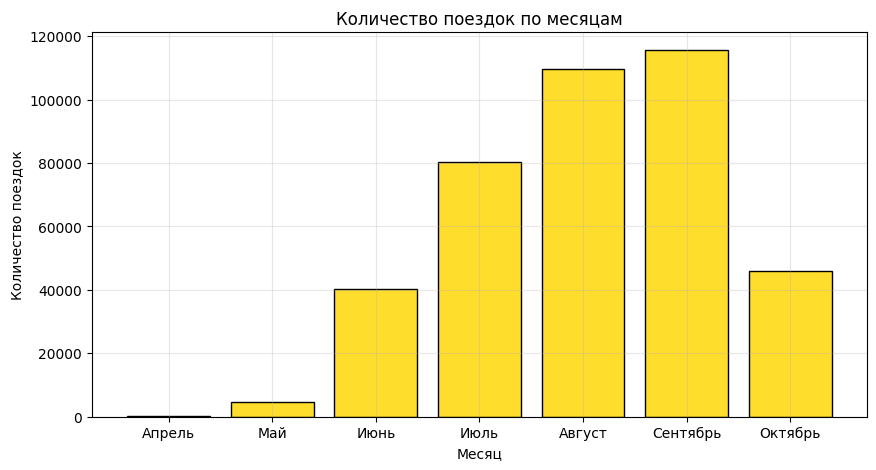

In [228]:
month_names = {1: "Январь", 2: "Февраль", 3: "Март", 4: "Апрель", 5: "Май", 6: "Июнь", 7: "Июль", 8: "Август", 9: "Сентябрь", 10: "Октябрь", 11: "Ноябрь", 12: "Декабрь"}

rides_by_month = df.groupby("ride_month")["order_rk"].count().reset_index()
rides_by_month["month_name"] = rides_by_month["ride_month"].map(month_names)

plt.figure(figsize=(10, 5))
plt.bar(rides_by_month["month_name"], rides_by_month["order_rk"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Месяц")
plt.ylabel("Количество поездок")
plt.title("Количество поездок по месяцам")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

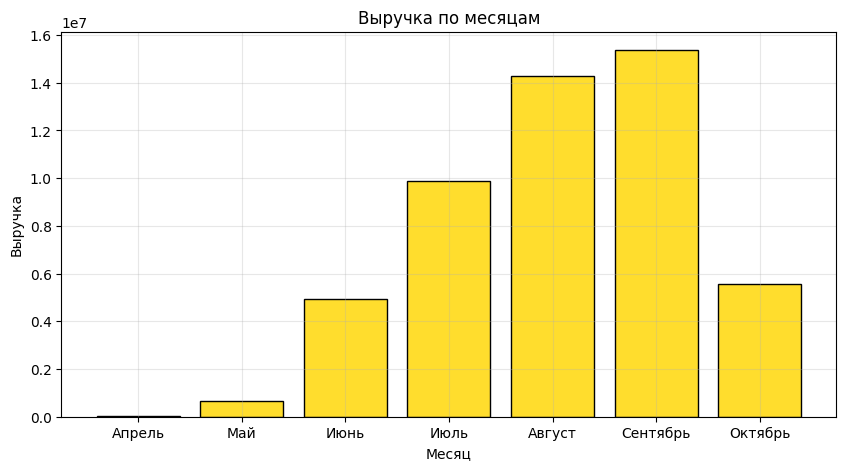

In [229]:
revenue_by_month = df.groupby("ride_month")["nominal_price_rub_amt"].sum().reset_index()
revenue_by_month["month_name"] = revenue_by_month["ride_month"].map(month_names)

plt.figure(figsize=(10, 5))
plt.bar(revenue_by_month["month_name"], revenue_by_month["nominal_price_rub_amt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Месяц")
plt.ylabel("Выручка")
plt.title("Выручка по месяцам")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

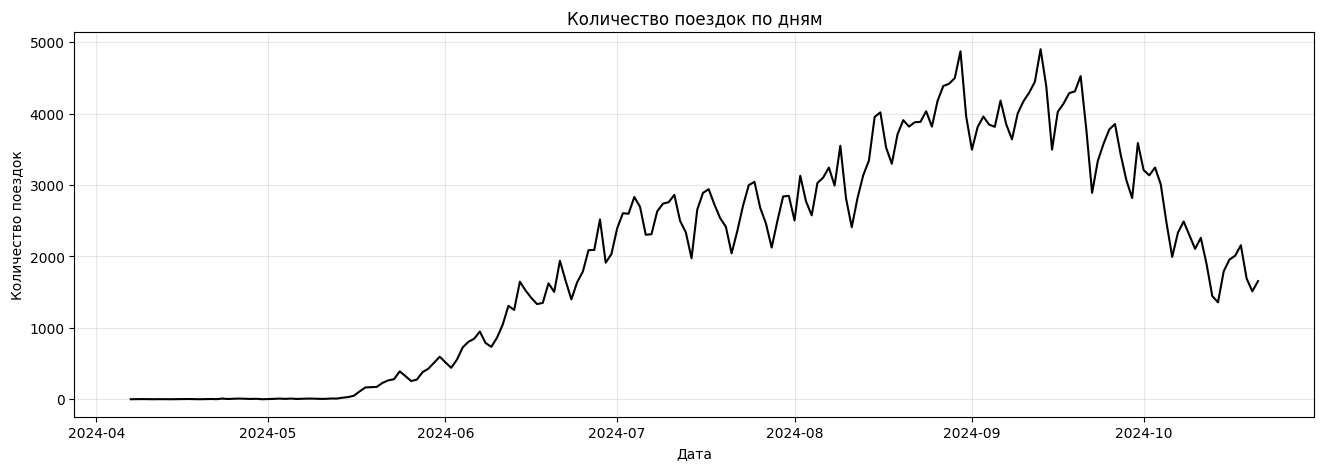

In [230]:
rides_by_day = df.groupby("ride_date")["order_rk"].count().reset_index()

plt.figure(figsize=(16, 5))
sns.lineplot(data=rides_by_day, x="ride_date", y="order_rk", color="black")
plt.xlabel("Дата")
plt.ylabel("Количество поездок")
plt.title("Количество поездок по дням")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

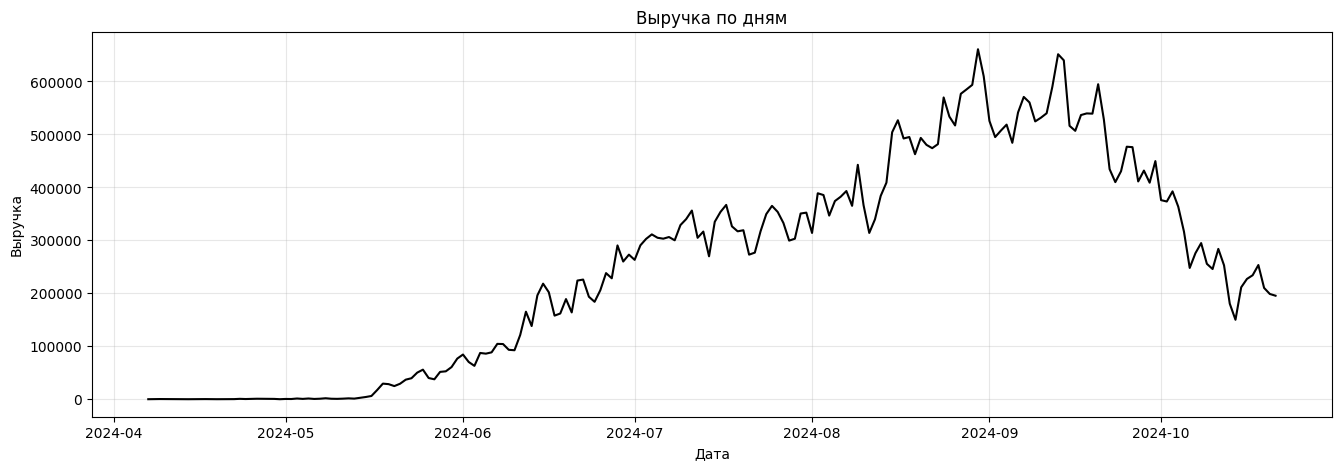

In [231]:
revenue_by_day = df.groupby("ride_date")["nominal_price_rub_amt"].sum().reset_index()

plt.figure(figsize=(16, 5))
sns.lineplot(data=revenue_by_day, x="ride_date", y="nominal_price_rub_amt", color="black")
plt.xlabel("Дата")
plt.ylabel("Выручка")
plt.title("Выручка по дням")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

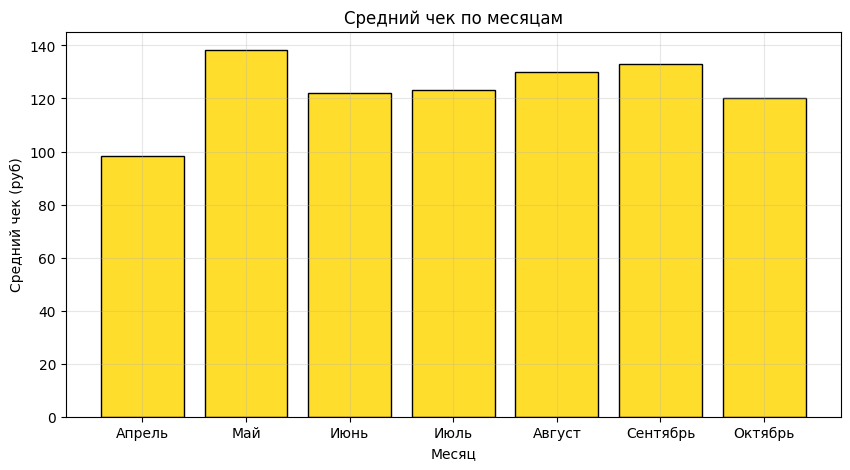

In [239]:
avg_check_by_month = df.groupby("ride_month")["nominal_price_rub_amt"].mean().reset_index()
avg_check_by_month["month_name"] = avg_check_by_month["ride_month"].map(month_names)

plt.figure(figsize=(10, 5))
plt.bar(avg_check_by_month["month_name"], avg_check_by_month["nominal_price_rub_amt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Месяц")
plt.ylabel("Средний чек (руб)")
plt.title("Средний чек по месяцам")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

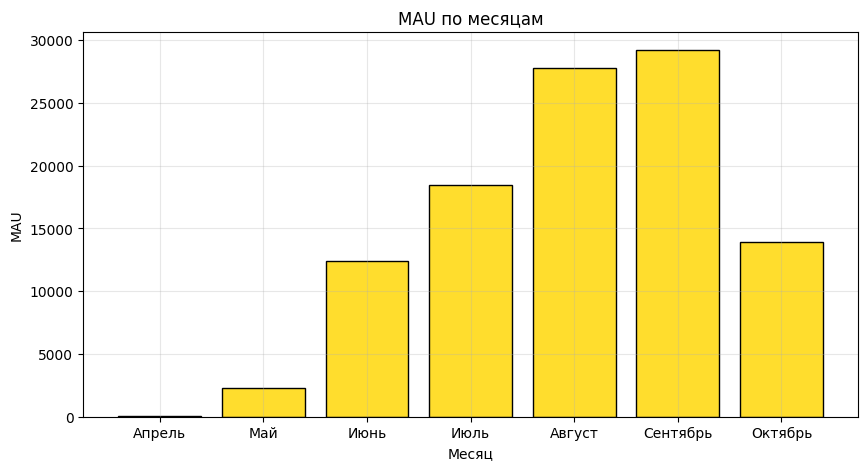

In [246]:
mau_by_month = df.groupby("ride_month")["party_rk"].nunique().reset_index()
mau_by_month["month_name"] = mau_by_month["ride_month"].map(month_names)

plt.figure(figsize=(10, 5))
plt.bar(mau_by_month["month_name"], mau_by_month["party_rk"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Месяц")
plt.ylabel("MAU")
plt.title("MAU по месяцам")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

## Временные штуки

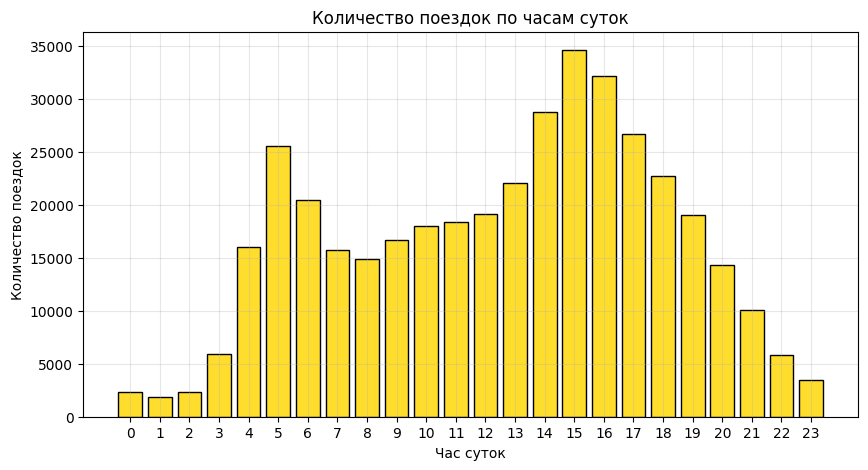

In [247]:
rides_by_hour = df.groupby("ride_hour")["order_rk"].count().reset_index()

plt.figure(figsize=(10, 5))
plt.bar(rides_by_hour["ride_hour"], rides_by_hour["order_rk"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Час суток")
plt.ylabel("Количество поездок")
plt.title("Количество поездок по часам суток")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

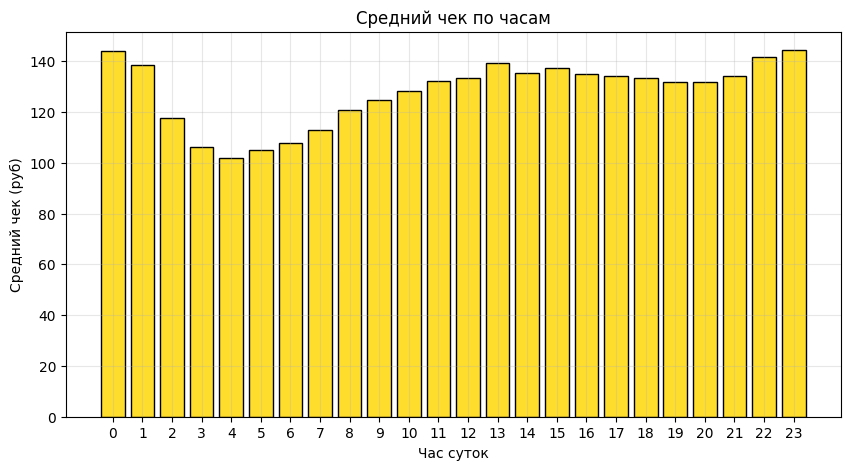

In [249]:
avg_check_by_hour = df.groupby("ride_hour")["nominal_price_rub_amt"].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.bar(avg_check_by_hour["ride_hour"], avg_check_by_hour["nominal_price_rub_amt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Час суток")
plt.ylabel("Средний чек (руб)")
plt.title("Средний чек по часам")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

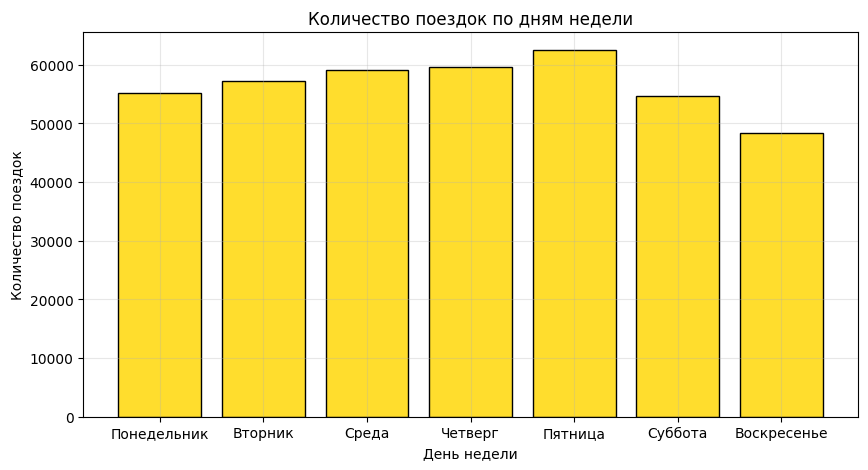

In [251]:
weekday_names = {0: "Понедельник", 1: "Вторник", 2: "Среда", 3: "Четверг", 4: "Пятница", 5: "Суббота", 6: "Воскресенье"}

rides_by_weekday = df.groupby("ride_dayofweek")["order_rk"].count().reset_index()
rides_by_weekday["weekday_name"] = rides_by_weekday["ride_dayofweek"].map(weekday_names)

plt.figure(figsize=(10, 5))
plt.bar(rides_by_weekday["weekday_name"], rides_by_weekday["order_rk"], color="#FFDD2D", edgecolor="black")
plt.xlabel("День недели")
plt.ylabel("Количество поездок")
plt.title("Количество поездок по дням недели")
plt.xticks()
plt.grid(alpha=0.3)
plt.show()

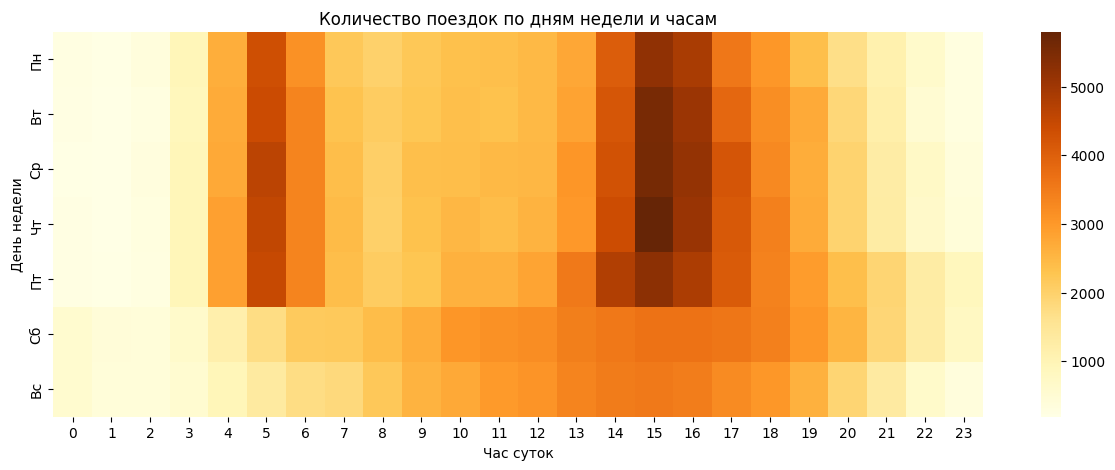

In [259]:
weekday_names = {0: "Пн", 1: "Вт", 2: "Ср", 3: "Чт", 4: "Пт", 5: "Сб", 6: "Вс"}

heatmap_data = df.pivot_table(index="ride_dayofweek", columns="ride_hour", values="order_rk", aggfunc="count")
heatmap_data.index = heatmap_data.index.map(weekday_names)

plt.figure(figsize=(15, 5))
sns.heatmap(heatmap_data, cmap="YlOrBr")
plt.xlabel("Час суток")
plt.ylabel("День недели")
plt.title("Количество поездок по дням недели и часам")
plt.show()

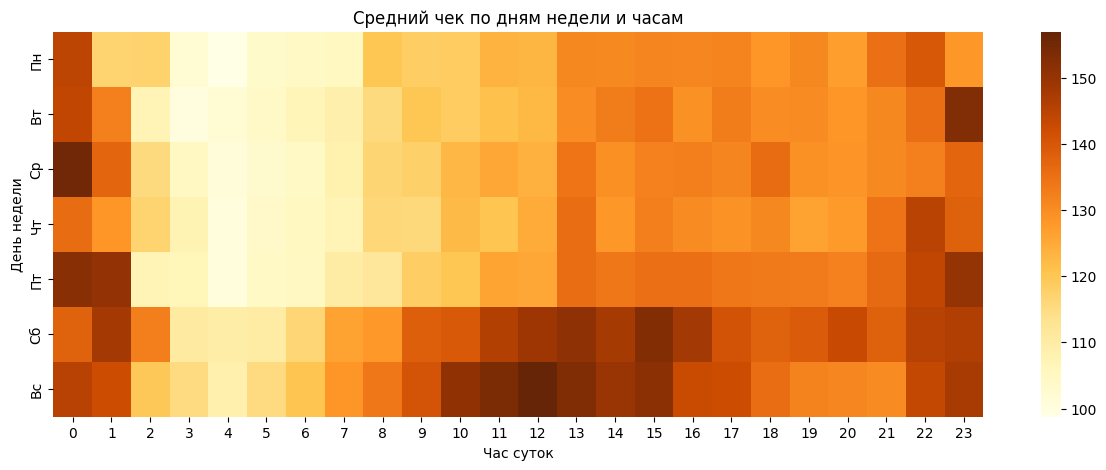

In [270]:
price_heatmap_data = df.pivot_table(index="ride_dayofweek", columns="ride_hour", values="nominal_price_rub_amt", aggfunc="mean")
price_heatmap_data.index = price_heatmap_data.index.map(weekday_names)

plt.figure(figsize=(15, 5))
sns.heatmap(price_heatmap_data, cmap="YlOrBr")
plt.xlabel("Час суток")
plt.ylabel("День недели")
plt.title("Средний чек по дням недели и часам")
plt.show()

In [262]:
df["average_speed"] = df["distance_km"] / (df["duration_min"] / 60)
df["is_anomaly"] = (df["average_speed"] > 35) | (df["duration_min"] > 180) | (df["distance_km"] > 30)

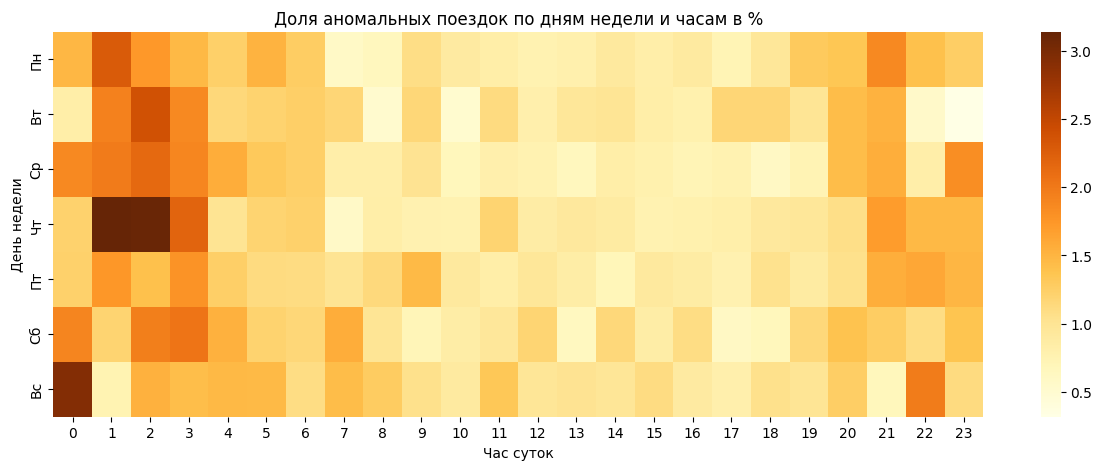

In [269]:
anomaly_heatmap_data = df.pivot_table(index="ride_dayofweek", columns="ride_hour", values="is_anomaly", aggfunc="mean") * 100
anomaly_heatmap_data.index = anomaly_heatmap_data.index.map(weekday_names)

plt.figure(figsize=(15, 5))
sns.heatmap(anomaly_heatmap_data, cmap="YlOrBr")
plt.xlabel("Час суток")
plt.ylabel("День недели")
plt.title("Доля аномальных поездок по дням недели и часам в %")
plt.show()

In [266]:
df["is_night"] = df["ride_hour"].between(0, 5)

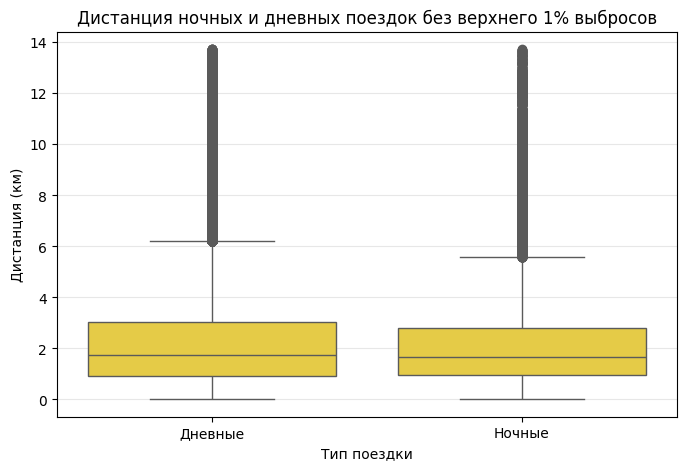

In [282]:
df_distance_box = df[df["distance_km"] <= df["distance_km"].quantile(0.99)]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_distance_box, x="is_night", y="distance_km", color="#FFDD2D")
plt.xlabel("Тип поездки")
plt.ylabel("Дистанция (км)")
plt.title("Дистанция ночных и дневных поездок без верхнего 1% выбросов")
plt.xticks([0, 1], ["Дневные", "Ночные"])
plt.grid(axis="y", alpha=0.3)
plt.show()

## География

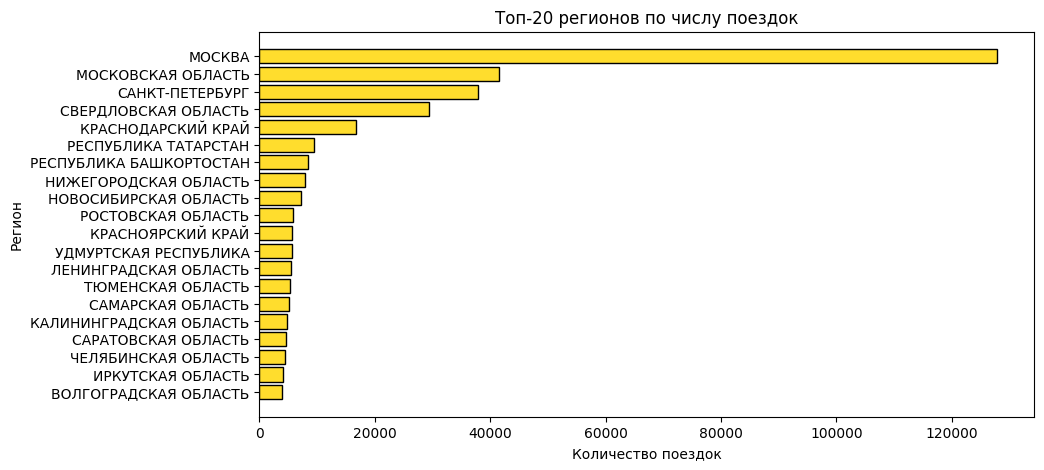

In [289]:
top_regions_rides = df["lvn_state_nm_clean"].value_counts().head(20).reset_index()
top_regions_rides.columns = ["region", "rides_cnt"]

plt.figure(figsize=(10, 5))
plt.barh(top_regions_rides["region"], top_regions_rides["rides_cnt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Количество поездок")
plt.ylabel("Регион")
plt.title("Tоп-20 регионов по числу поездок")
plt.gca().invert_yaxis() # gca - get current axis (типа взять текущую ось), invert_yaxis - перевернуть y ось
plt.show()

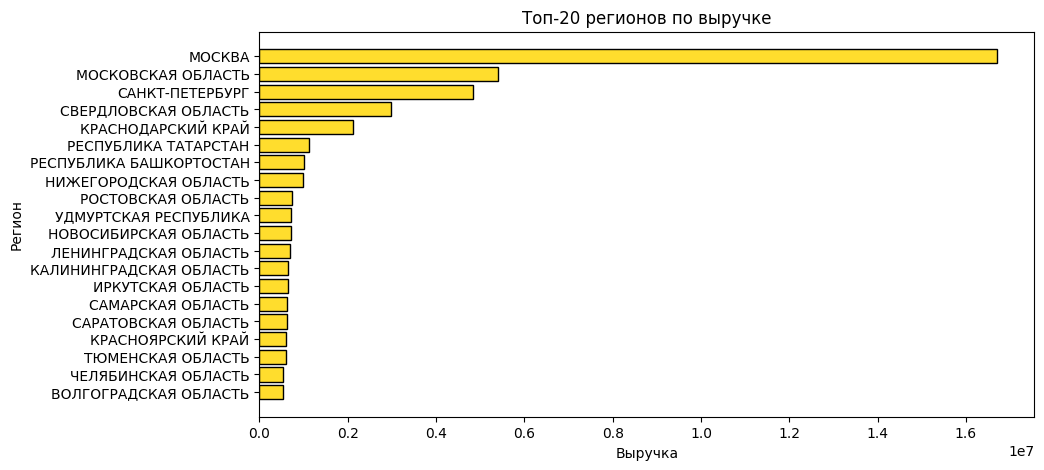

In [296]:
top_regions_revenue = df.groupby("lvn_state_nm_clean")["nominal_price_rub_amt"].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 5))
plt.barh(top_regions_revenue.index, top_regions_revenue.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Выручка")
plt.ylabel("Регион")
plt.title("Топ-20 регионов по выручке")
plt.gca().invert_yaxis()
plt.show()

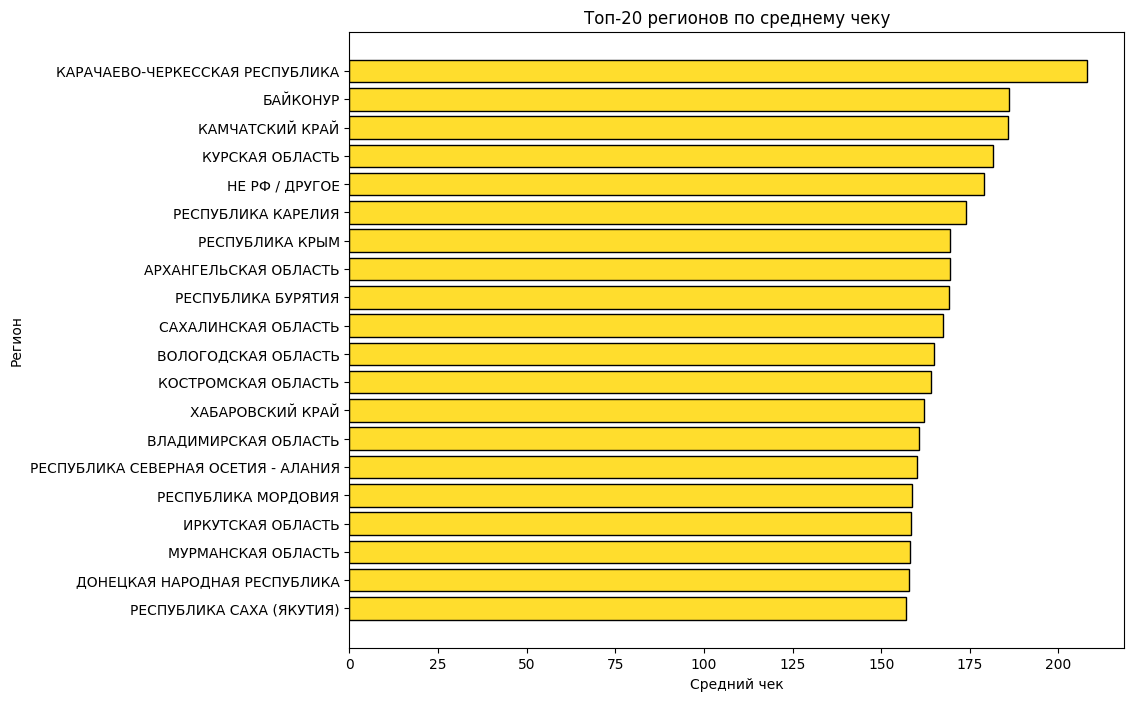

In [315]:
avg_check_by_region = df.groupby("lvn_state_nm_clean")["nominal_price_rub_amt"].mean().sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 8))
plt.barh(avg_check_by_region.index, avg_check_by_region.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Средний чек")
plt.ylabel("Регион")
plt.title("Tоп-20 регионов по среднему чеку")
plt.gca().invert_yaxis()
plt.show()

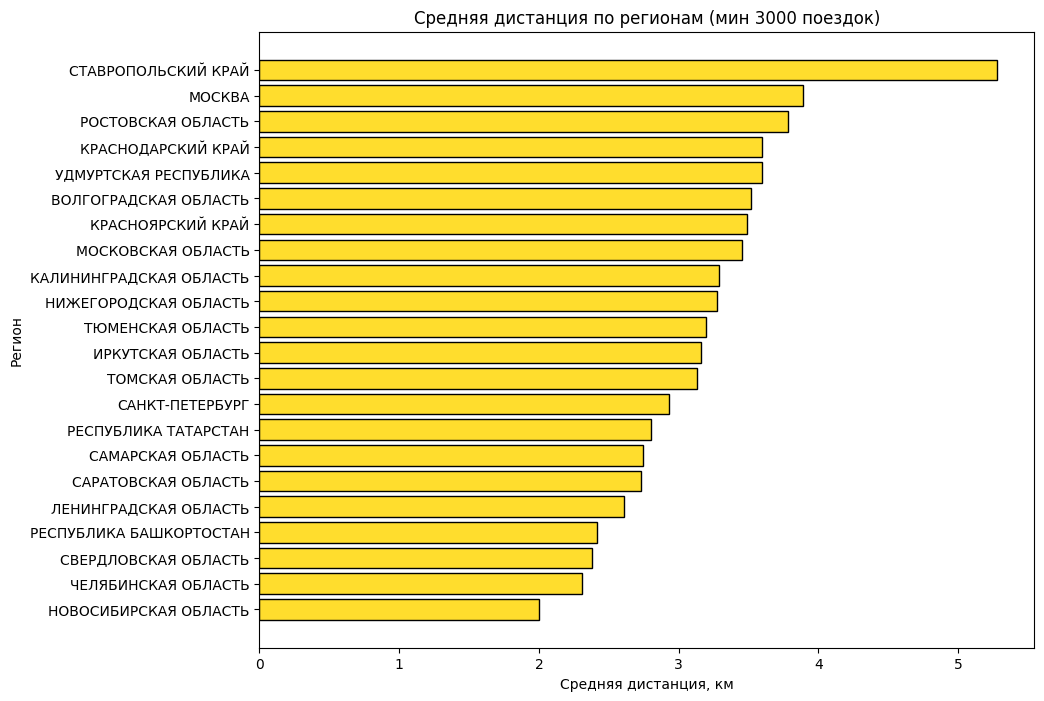

In [306]:
region_stats = df.groupby("lvn_state_nm_clean").agg(rides_cnt=("order_rk", "count"), avg_distance=("distance_km", "mean")).reset_index()
region_stats = region_stats[region_stats["rides_cnt"] >= 3000].sort_values("avg_distance", ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(region_stats["lvn_state_nm_clean"], region_stats["avg_distance"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Средняя дистанция, км")
plt.ylabel("Регион")
plt.title("Средняя дистанция по регионам (мин 3000 поездок)")
plt.gca().invert_yaxis()
plt.show()

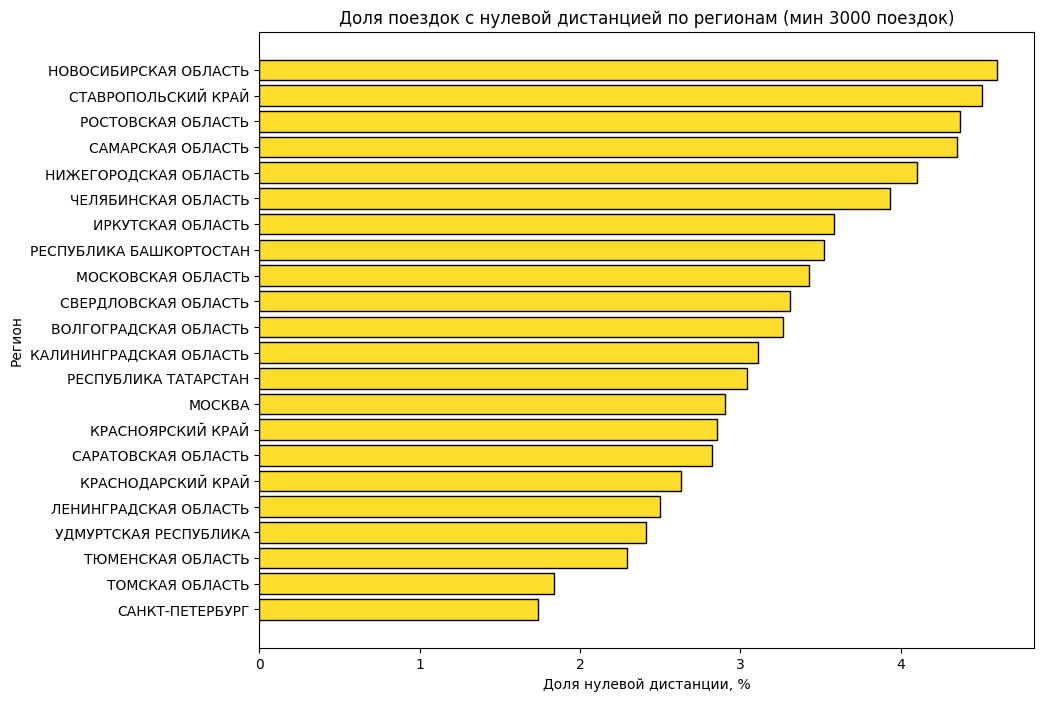

In [314]:
df["zero_distance"] = df["distance_km"] == 0

zero_distance_share = df.groupby("lvn_state_nm_clean")["zero_distance"].mean() * 100
region_counts = df["lvn_state_nm_clean"].value_counts()
zero_distance_share = zero_distance_share[region_counts >= 3000].sort_values(ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(zero_distance_share.index, zero_distance_share.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Доля нулевой дистанции, %")
plt.ylabel("Регион")
plt.title("Доля поездок с нулевой дистанцией по регионам (мин 3000 поездок)")
plt.gca().invert_yaxis()
plt.show()

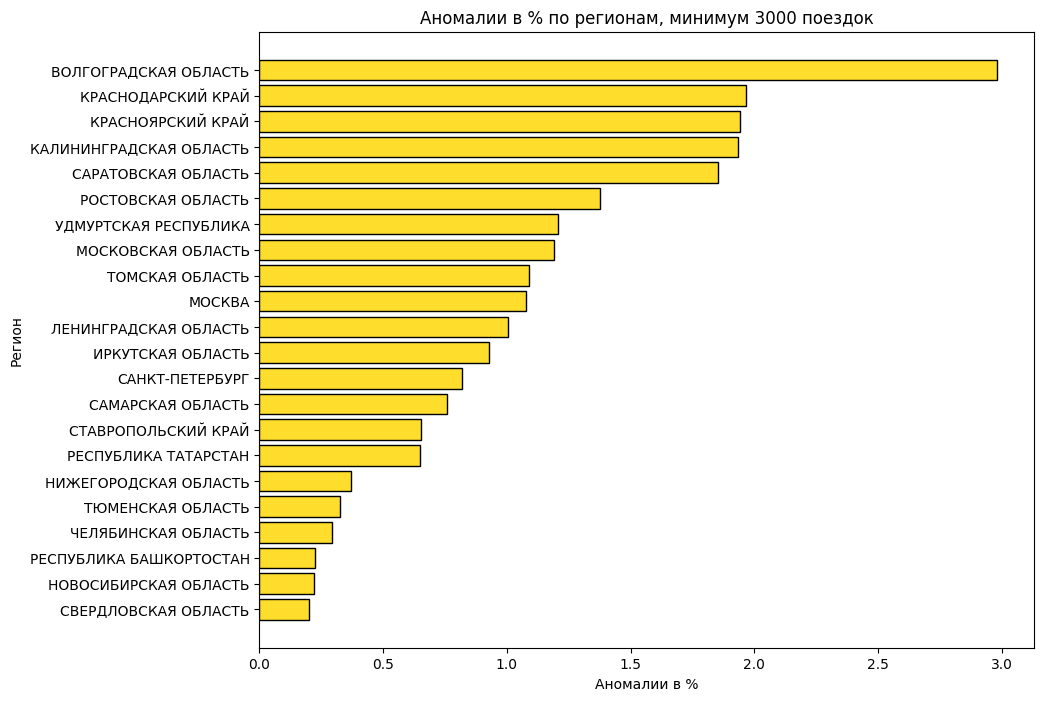

In [321]:
anomaly_rate = df.groupby("lvn_state_nm_clean")["is_anomaly"].mean() * 100
region_counts = df["lvn_state_nm_clean"].value_counts()

anomaly_rate = anomaly_rate[region_counts >= 3000].sort_values(ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(anomaly_rate.index, anomaly_rate.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Аномалии в %")
plt.ylabel("Регион")
plt.title("Аномалии в % по регионам, минимум 3000 поездок")
plt.gca().invert_yaxis()
plt.show()

## Транспортные модели

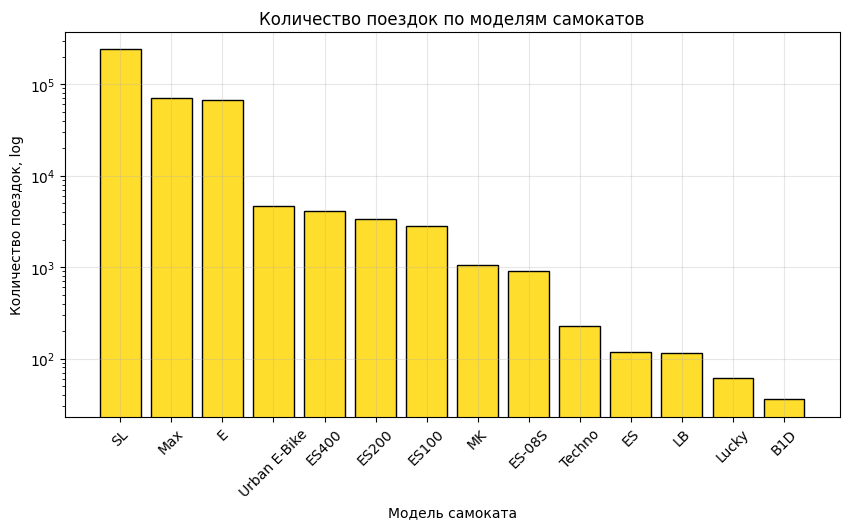

In [325]:
rides_by_model = df["transport_model"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(rides_by_model.index, rides_by_model.values, color="#FFDD2D", edgecolor="black")
plt.yscale("log")
plt.xlabel("Модель самоката")
plt.ylabel("Количество поездок, log")
plt.title("Количество поездок по моделям самокатов")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

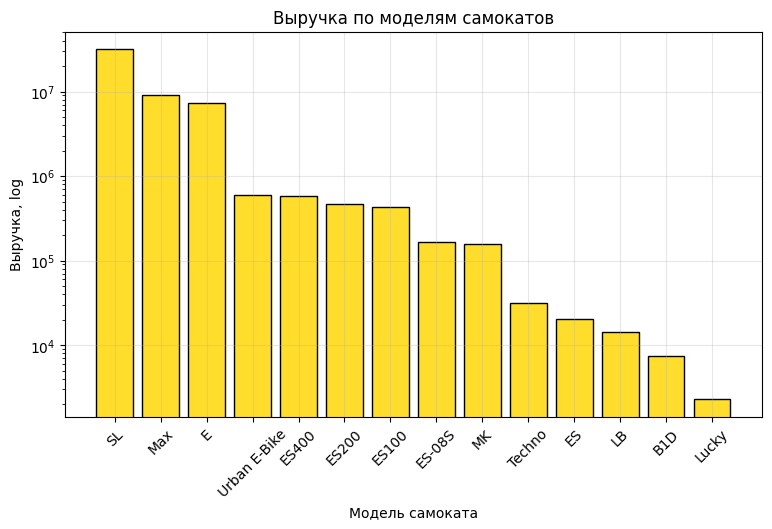

In [329]:
revenue_by_model = df.groupby("transport_model")["nominal_price_rub_amt"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(revenue_by_model.index, revenue_by_model.values, color="#FFDD2D", edgecolor="black")
plt.yscale("log")
plt.xlabel("Модель самоката")
plt.ylabel("Выручка, log")
plt.title("Выручка по моделям самокатов")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

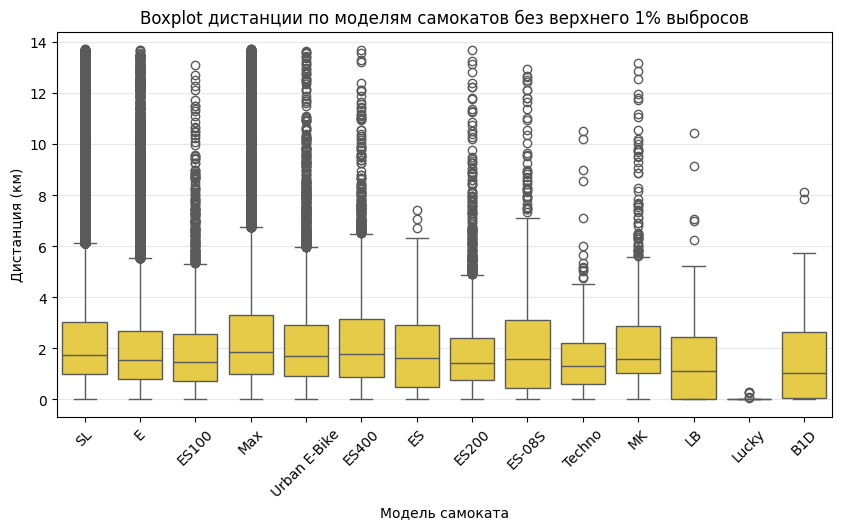

In [336]:
distance_limit = df["distance_km"].quantile(0.99)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["distance_km"] <= distance_limit], x="transport_model", y="distance_km", color="#FFDD2D")
plt.xlabel("Модель самоката")
plt.ylabel("Дистанция (км)")
plt.title("Boxplot дистанции по моделям самокатов без верхнего 1% выбросов")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

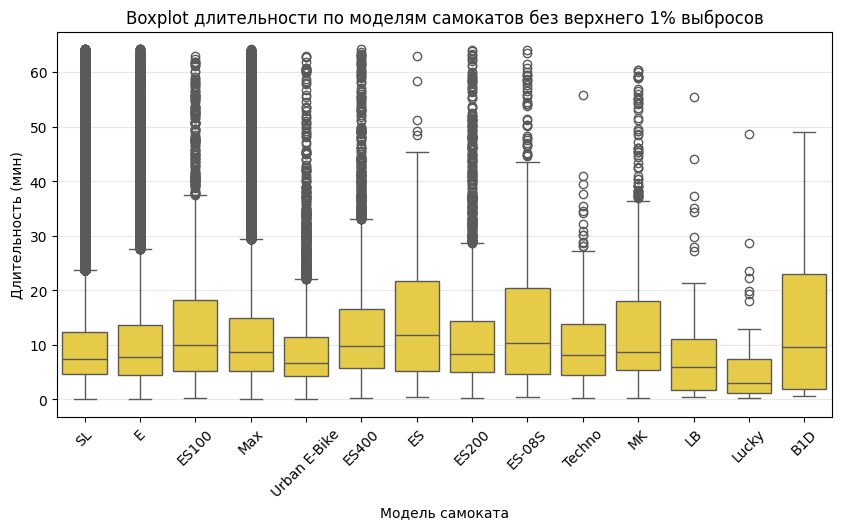

In [338]:
duration_limit = df["duration_min"].quantile(0.99)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["duration_min"] <= duration_limit], x="transport_model", y="duration_min", color="#FFDD2D")
plt.xlabel("Модель самоката")
plt.ylabel("Длительность (мин)")
plt.title("Boxplot длительности по моделям самокатов без верхнего 1% выбросов")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

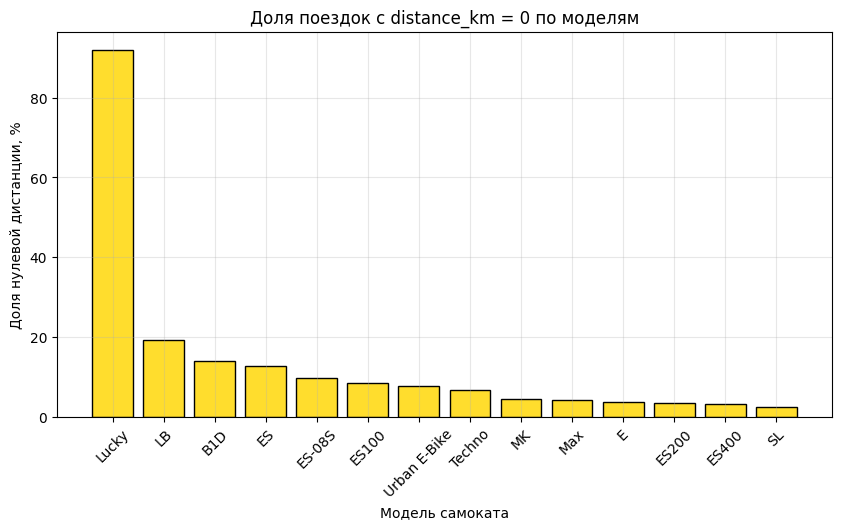

In [343]:
df["zero_distance"] = df["distance_km"] == 0

zero_distance_by_model = df.groupby("transport_model")["zero_distance"].mean() * 100
zero_distance_by_model = zero_distance_by_model.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(zero_distance_by_model.index, zero_distance_by_model.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Модель самоката")
plt.ylabel("Доля нулевой дистанции, %")
plt.title("Доля поездок с distance_km = 0 по моделям")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

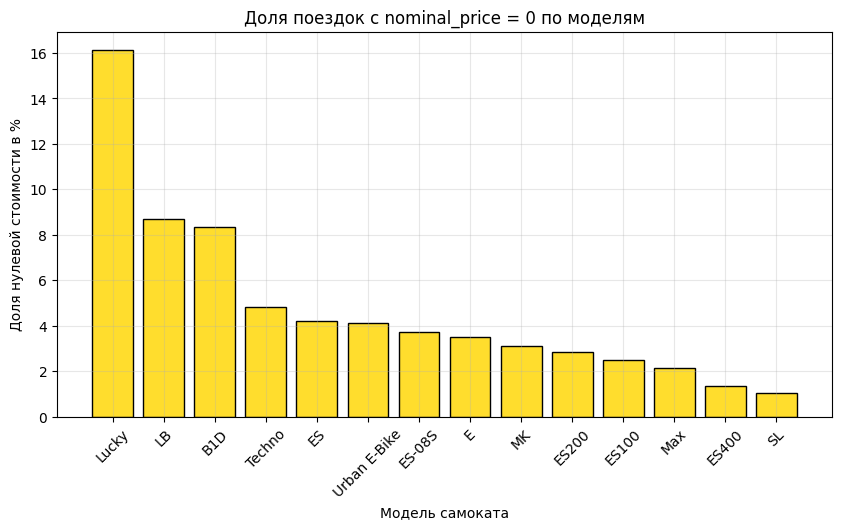

In [342]:
df["zero_price"] = (df["nominal_price_rub_amt"] == 0).astype(int)

zero_price_by_model = df.groupby("transport_model")["zero_price"].mean() * 100
zero_price_by_model = zero_price_by_model.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(zero_price_by_model.index, zero_price_by_model.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Модель самоката")
plt.ylabel("Доля нулевой стоимости в %")
plt.title("Доля поездок с nominal_price = 0 по моделям")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

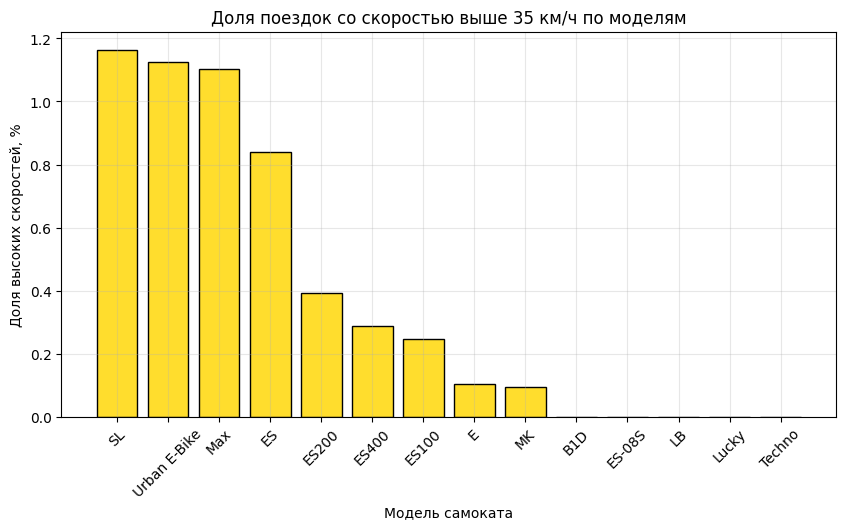

In [350]:
df["avg_speed_kmh"] = df["distance_km"] / (df["duration_min"] / 60)
df["high_speed"] = (df["avg_speed_kmh"] > 35)

high_speed_by_model = df.groupby("transport_model")["high_speed"].mean() * 100
high_speed_by_model = high_speed_by_model.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(high_speed_by_model.index, high_speed_by_model.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Модель самоката")
plt.ylabel("Доля высоких скоростей, %")
plt.title("Доля поездок со скоростью выше 35 км/ч по моделям")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

In [352]:
df["model_group"] = "Остальные"
df.loc[df["transport_model"] == "Lucky", "model_group"] = "Lucky"

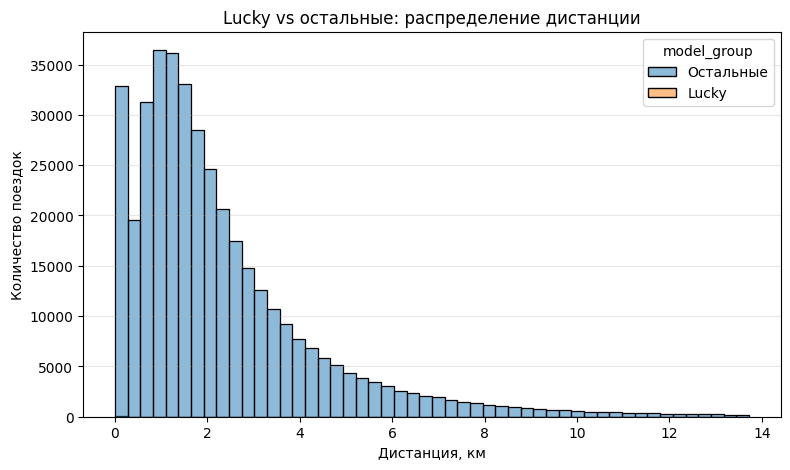

In [353]:
distance_limit = df["distance_km"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["distance_km"] <= distance_limit], x="distance_km", hue="model_group", bins=50)
plt.xlabel("Дистанция, км")
plt.ylabel("Количество поездок")
plt.title("Lucky vs остальные: распределение дистанции")
plt.grid(axis="y", alpha=0.3)
plt.show()

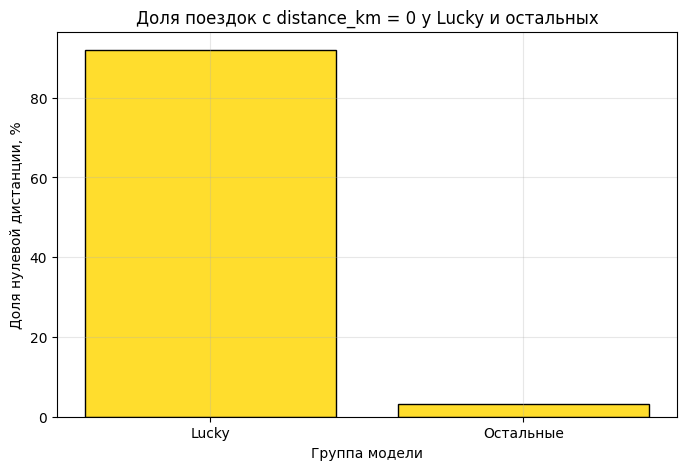

In [361]:
df["model_group"] = "Остальные"
df.loc[df["transport_model"] == "Lucky", "model_group"] = "Lucky"

df["zero_distance"] = df["distance_km"] == 0

zero_distance_by_group = df.groupby("model_group")["zero_distance"].mean() * 100

plt.figure(figsize=(8, 5))
plt.bar(zero_distance_by_group.index, zero_distance_by_group.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Группа модели")
plt.ylabel("Доля нулевой дистанции, %")
plt.title("Доля поездок с distance_km = 0 у Lucky и остальных")
plt.grid(alpha=0.3)
plt.show()

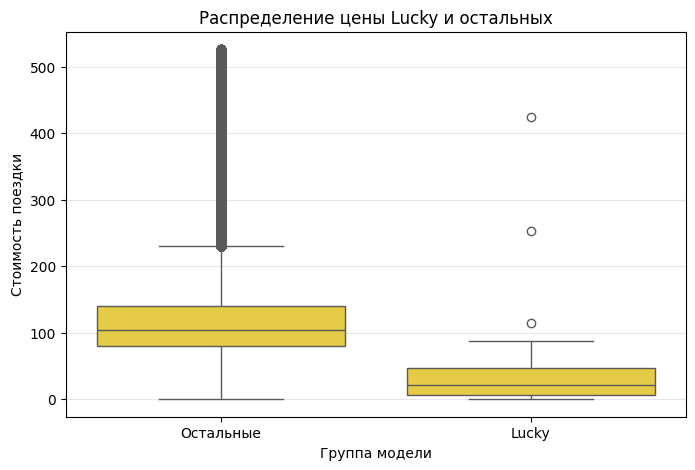

In [363]:
df["model_group"] = "Остальные"
df.loc[df["transport_model"] == "Lucky", "model_group"] = "Lucky"

price_limit = df["nominal_price_rub_amt"].quantile(0.99)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df[df["nominal_price_rub_amt"] <= price_limit], x="model_group", y="nominal_price_rub_amt", color="#FFDD2D")
plt.xlabel("Группа модели")
plt.ylabel("Стоимость поездки")
plt.title("Распределение цены Lucky и остальных")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Распределения

In [368]:
clients = df.drop_duplicates(subset="party_rk")

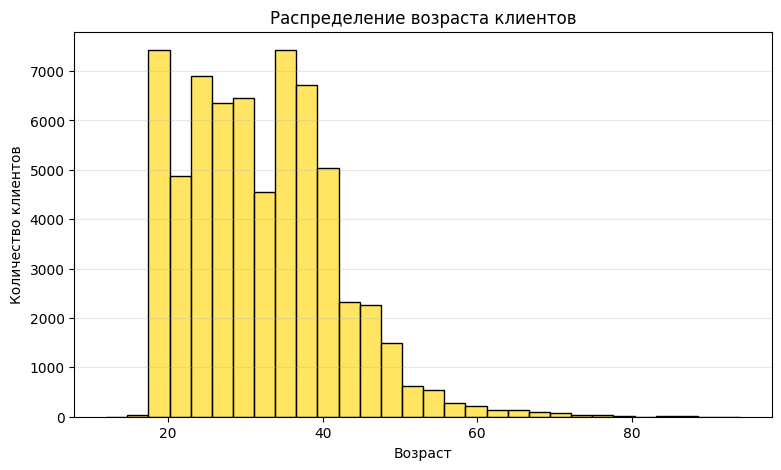

In [369]:
plt.figure(figsize=(9, 5))
sns.histplot(data=clients, x="age", bins=30, color="#FFDD2D", edgecolor="black")
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.title("Распределение возраста клиентов")
plt.grid(axis="y", alpha=0.3)
plt.show()

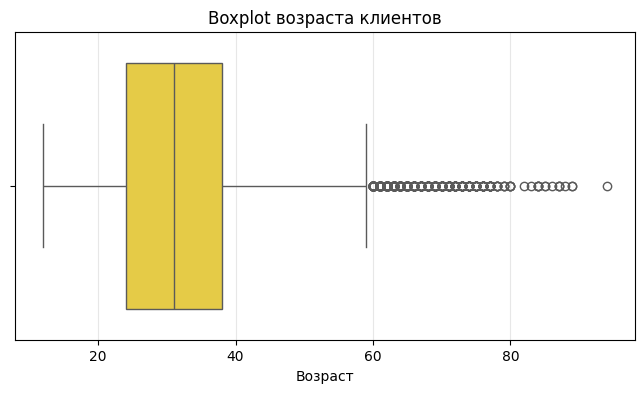

In [370]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=clients, x="age", color="#FFDD2D")
plt.xlabel("Возраст")
plt.title("Boxplot возраста клиентов")
plt.grid(axis="x", alpha=0.3)
plt.show()

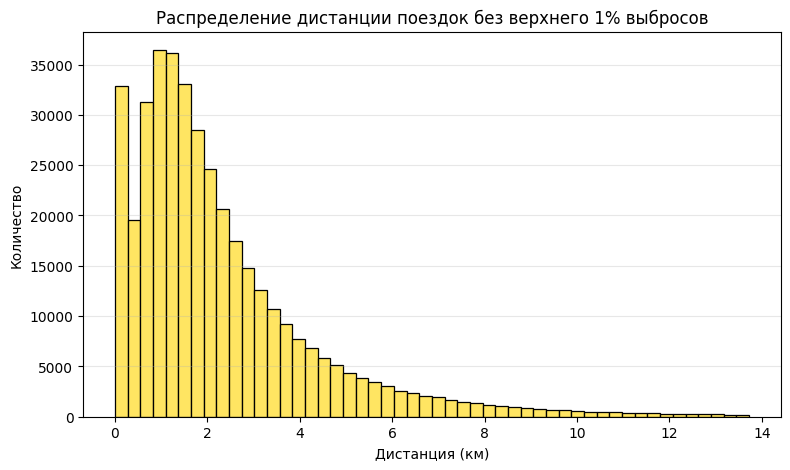

In [380]:
distance_limit = df["distance_km"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["distance_km"] <= distance_limit], x="distance_km", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Дистанция (км)")
plt.ylabel("Количество")
plt.title("Распределение дистанции поездок без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

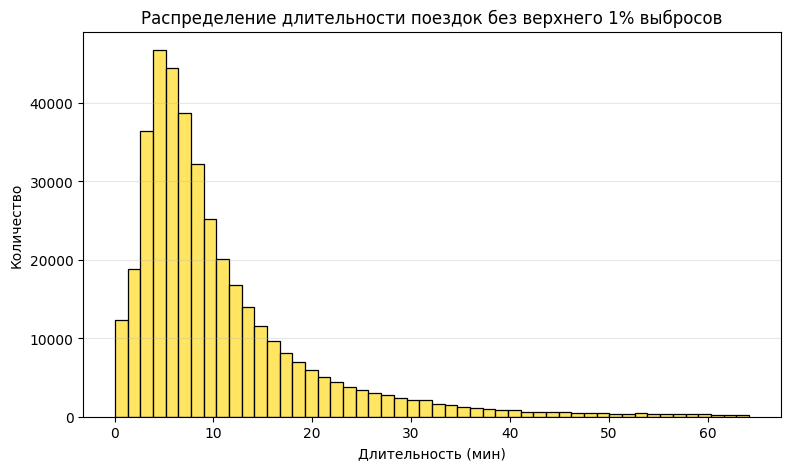

In [379]:
duration_limit = df["duration_min"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["duration_min"] <= duration_limit], x="duration_min", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Длительность (мин)")
plt.ylabel("Количество")
plt.title("Распределение длительности поездок без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

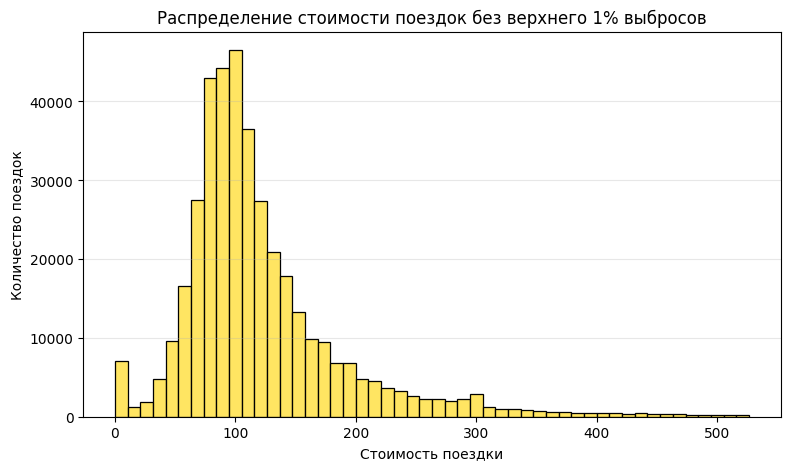

In [382]:
price_limit = df["nominal_price_rub_amt"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["nominal_price_rub_amt"] <= price_limit], x="nominal_price_rub_amt", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Стоимость поездки")
plt.ylabel("Количество поездок")
plt.title("Распределение стоимости поездок без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

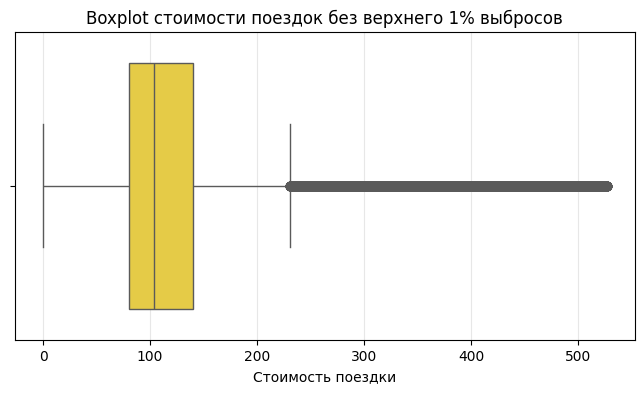

In [383]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["nominal_price_rub_amt"] <= price_limit], x="nominal_price_rub_amt", color="#FFDD2D")
plt.xlabel("Стоимость поездки")
plt.title("Boxplot стоимости поездок без верхнего 1% выбросов")
plt.grid(axis="x", alpha=0.3)
plt.show()

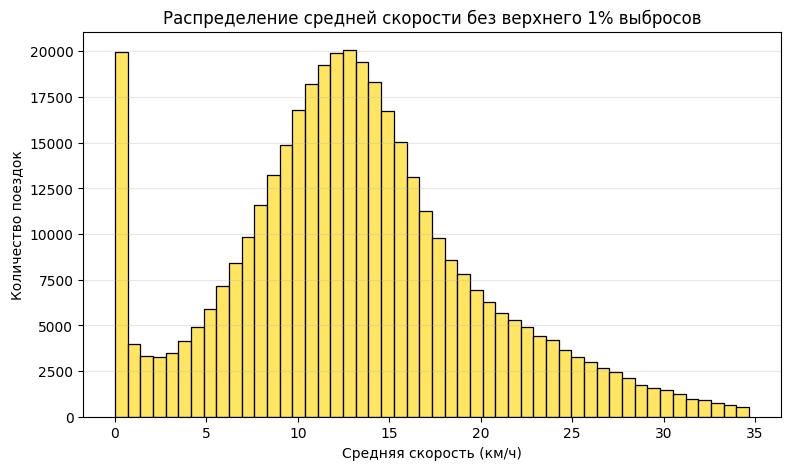

In [385]:
df["avg_speed_kmh"] = df["distance_km"] / (df["duration_min"] / 60)
df["avg_speed_kmh"] = df["avg_speed_kmh"].replace([np.inf, -np.inf], np.nan)

speed_limit = df["avg_speed_kmh"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["avg_speed_kmh"] <= speed_limit], x="avg_speed_kmh", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Средняя скорость (км/ч)")
plt.ylabel("Количество поездок")
plt.title("Распределение средней скорости без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

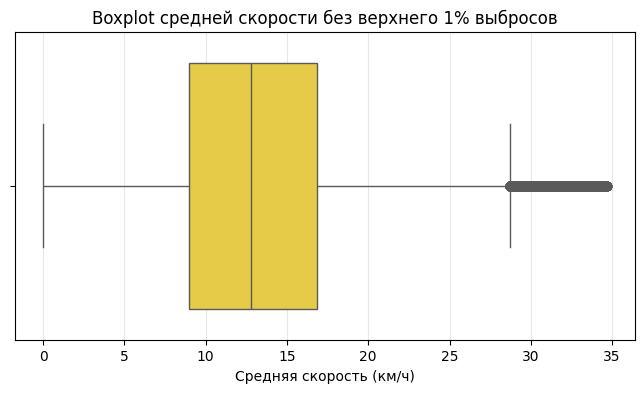

In [390]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["avg_speed_kmh"] <= speed_limit], x="avg_speed_kmh", color="#FFDD2D")
plt.xlabel("Средняя скорость (км/ч)")
plt.title("Boxplot средней скорости без верхнего 1% выбросов")
plt.grid(axis="x", alpha=0.3)
plt.show()

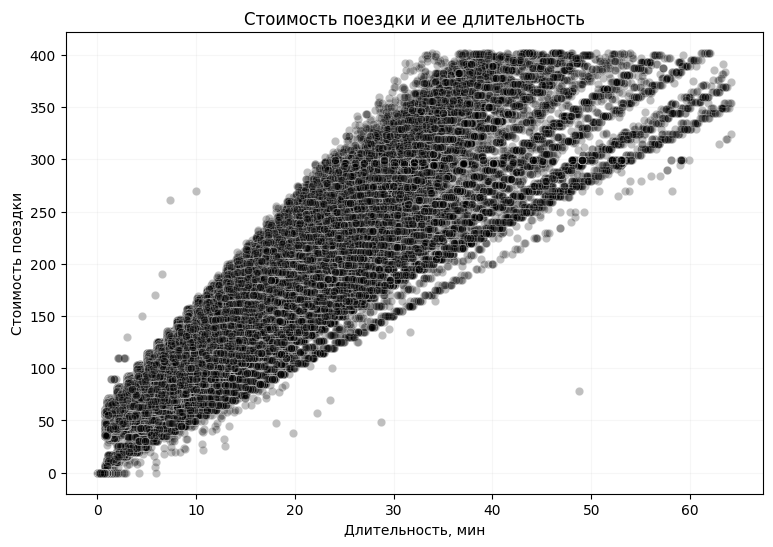

In [389]:
scatter_df = df[df["duration_min"] <= df["duration_min"].quantile(0.99)]
scatter_df = scatter_df[scatter_df["nominal_price_rub_amt"] <= scatter_df["nominal_price_rub_amt"].quantile(0.99)]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x="duration_min", y="nominal_price_rub_amt", color="black", alpha=0.25)
plt.xlabel("Длительность, мин")
plt.ylabel("Стоимость поездки")
plt.title("Стоимость поездки и ее длительность")
plt.grid(alpha=0.1)
plt.show()

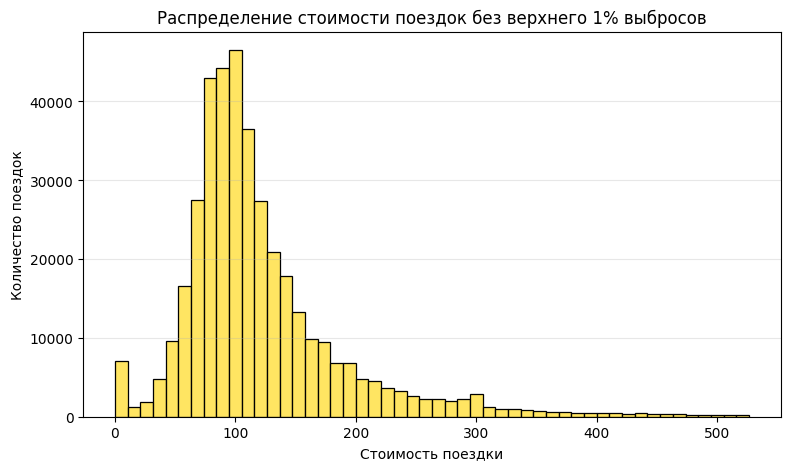

In [392]:
price_limit = df["nominal_price_rub_amt"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["nominal_price_rub_amt"] <= price_limit], x="nominal_price_rub_amt", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Стоимость поездки")
plt.ylabel("Количество поездок")
plt.title("Распределение стоимости поездок без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

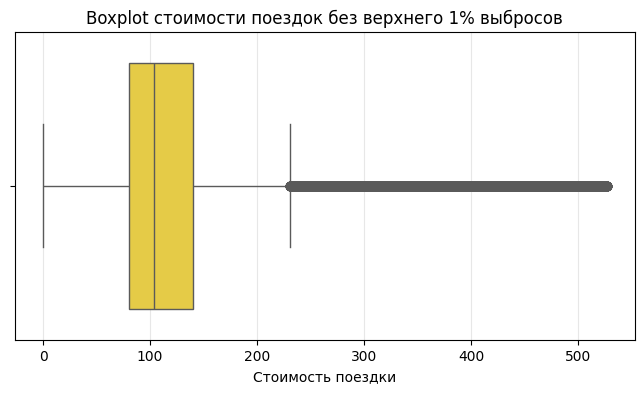

In [393]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["nominal_price_rub_amt"] <= price_limit], x="nominal_price_rub_amt", color="#FFDD2D")
plt.xlabel("Стоимость поездки")
plt.title("Boxplot стоимости поездок без верхнего 1% выбросов")
plt.grid(axis="x", alpha=0.3)
plt.show()

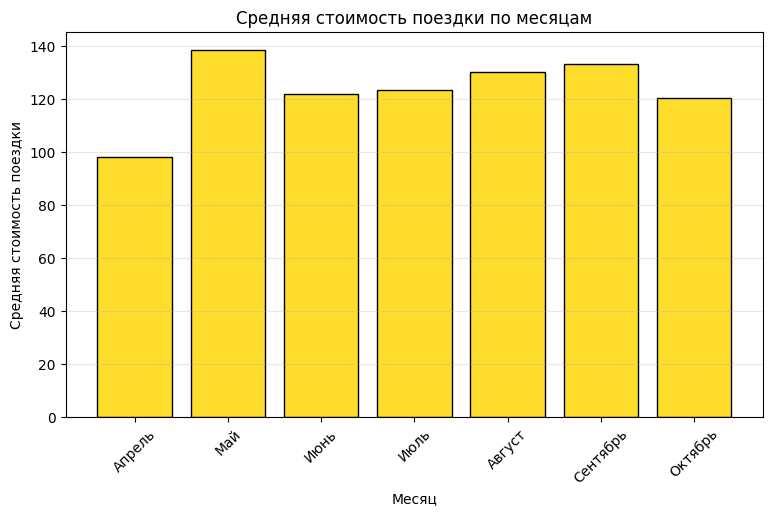

In [394]:
price_by_month = df.groupby("ride_month")["nominal_price_rub_amt"].mean().reset_index()
price_by_month["month_name"] = price_by_month["ride_month"].map(month_names)

plt.figure(figsize=(9, 5))
plt.bar(price_by_month["month_name"], price_by_month["nominal_price_rub_amt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Месяц")
plt.ylabel("Средняя стоимость поездки")
plt.title("Средняя стоимость поездки по месяцам")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

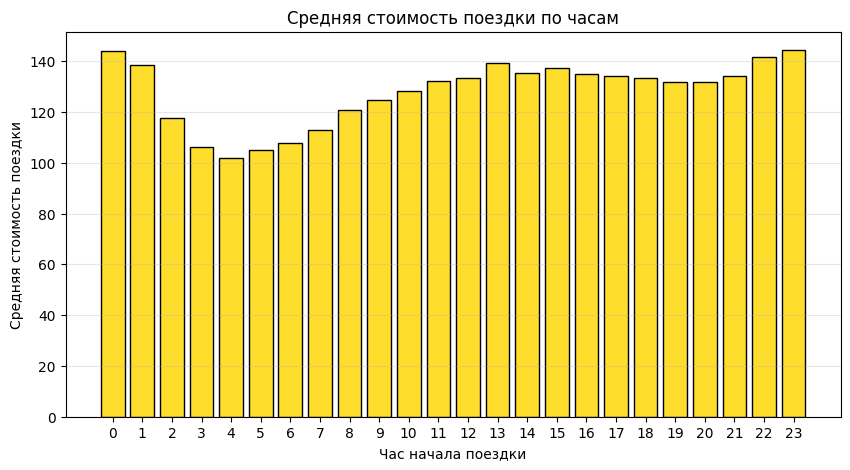

In [395]:
price_by_hour = df.groupby("ride_hour")["nominal_price_rub_amt"].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.bar(price_by_hour["ride_hour"], price_by_hour["nominal_price_rub_amt"], color="#FFDD2D", edgecolor="black")
plt.xlabel("Час начала поездки")
plt.ylabel("Средняя стоимость поездки")
plt.title("Средняя стоимость поездки по часам")
plt.xticks(range(0, 24))
plt.grid(axis="y", alpha=0.3)
plt.show()

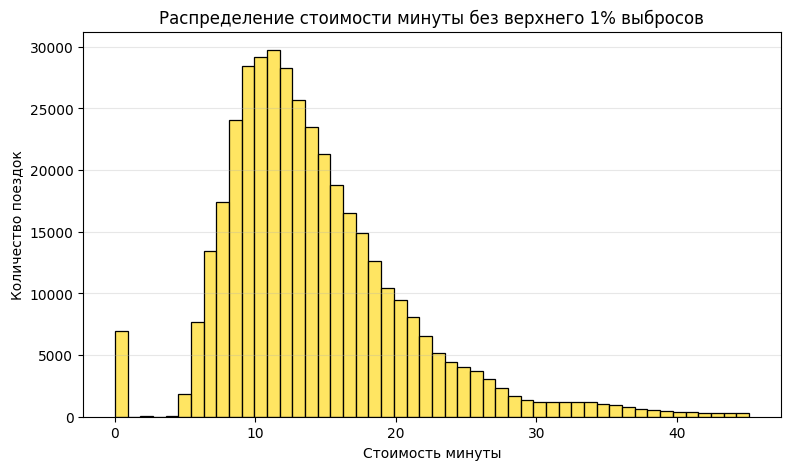

In [396]:
df["price_per_min"] = df["nominal_price_rub_amt"] / df["duration_min"]
df["price_per_min"] = df["price_per_min"].replace([np.inf, -np.inf], np.nan)

price_per_min_limit = df["price_per_min"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["price_per_min"] <= price_per_min_limit], x="price_per_min", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Стоимость минуты")
plt.ylabel("Количество поездок")
plt.title("Распределение стоимости минуты без верхнего 1% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

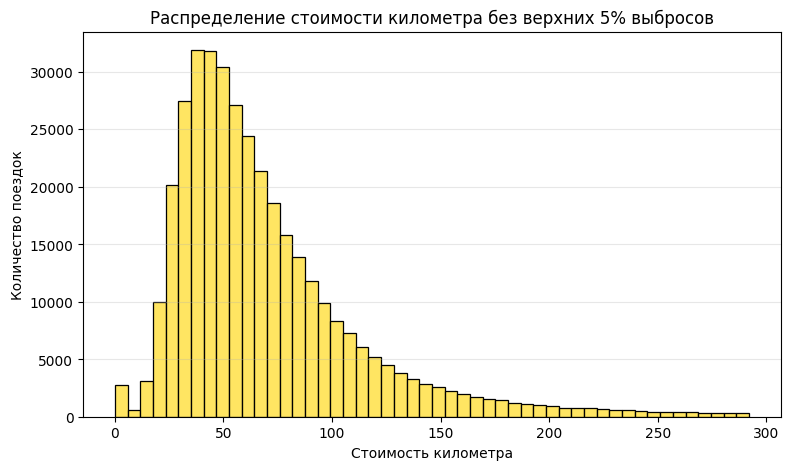

In [401]:
df["price_per_km"] = df["nominal_price_rub_amt"] / df["distance_km"]
df["price_per_km"] = df["price_per_km"].replace([np.inf, -np.inf], np.nan)

price_per_km_limit = df["price_per_km"].quantile(0.95)

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["price_per_km"] <= price_per_km_limit], x="price_per_km", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Стоимость километра")
plt.ylabel("Количество поездок")
plt.title("Распределение стоимости километра без верхних 5% выбросов")
plt.grid(axis="y", alpha=0.3)
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


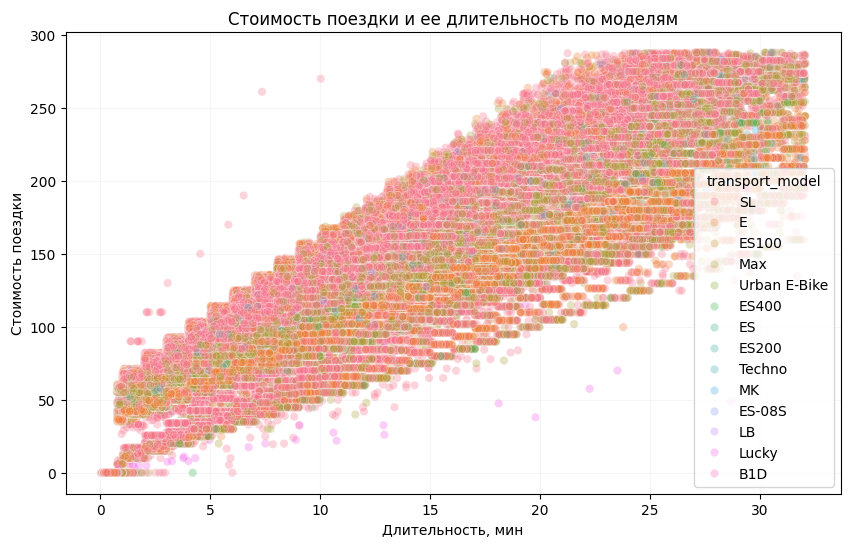

In [405]:
scatter_df = df[df["duration_min"] <= df["duration_min"].quantile(0.95)]
scatter_df = scatter_df[scatter_df["nominal_price_rub_amt"] <= scatter_df["nominal_price_rub_amt"].quantile(0.99)]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=scatter_df, x="duration_min", y="nominal_price_rub_amt", hue="transport_model", alpha=0.3)
plt.xlabel("Длительность, мин")
plt.ylabel("Стоимость поездки")
plt.title("Стоимость поездки и ее длительность по моделям")
plt.grid(alpha=0.1)
plt.show()

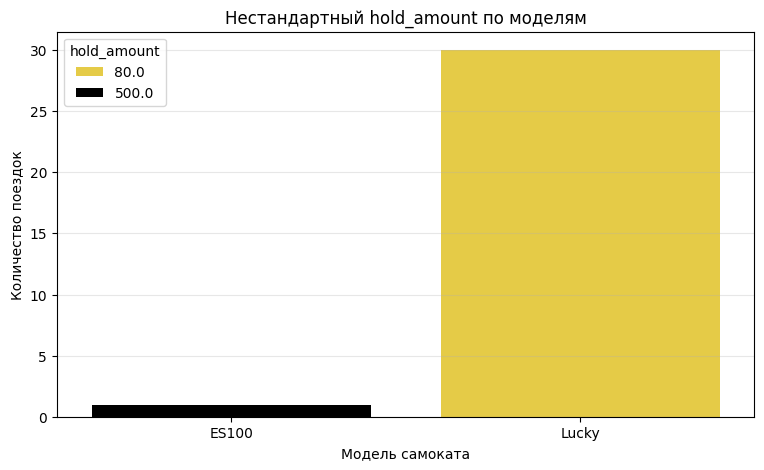

In [418]:
nonstandard_hold_df = df[df["hold_amount"] != 300]

hold_by_model = nonstandard_hold_df.groupby(["transport_model", "hold_amount"]).size().reset_index(name="rides_cnt")

plt.figure(figsize=(9, 5))
sns.barplot(data=hold_by_model, x="transport_model", y="rides_cnt", hue="hold_amount", palette=["#FFDD2D", "black"])
plt.xlabel("Модель самоката")
plt.ylabel("Количество поездок")
plt.title("Нестандартный hold_amount по моделям")
plt.xticks()
plt.grid(axis="y", alpha=0.3)
plt.show()

# Аномалии, антифрод

In [413]:
df["anomaly_speed"] = df["avg_speed_kmh"] > 35
df["anomaly_duration"] = df["duration_min"] > 180
df["anomaly_distance"] = df["distance_km"] > 30
df["anomaly_zero_distance_long_time"] = (df["distance_km"] == 0) & (df["duration_min"] > 5)

df["rule_anomaly"] = ((df["anomaly_speed"] == 1) | (df["anomaly_duration"] == 1) | (df["anomaly_distance"] == 1) | (df["anomaly_zero_distance_long_time"] == 1)).astype(int)

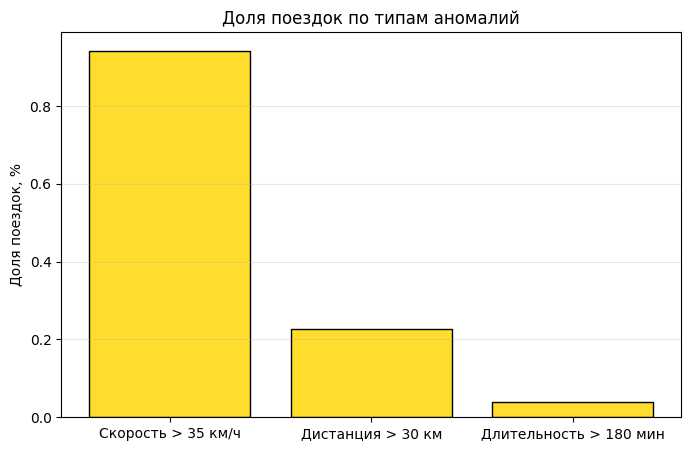

In [417]:
anomaly_reasons = pd.Series({"Скорость > 35 км/ч": df["anomaly_speed"].mean() * 100, "Длительность > 180 мин": df["anomaly_duration"].mean() * 100, "Дистанция > 30 км": df["anomaly_distance"].mean() * 100}).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(anomaly_reasons.index, anomaly_reasons.values, color="#FFDD2D", edgecolor="black")
plt.ylabel("Доля поездок, %")
plt.title("Доля поездок по типам аномалий")
plt.xticks()
plt.grid(axis="y", alpha=0.3)
plt.show()

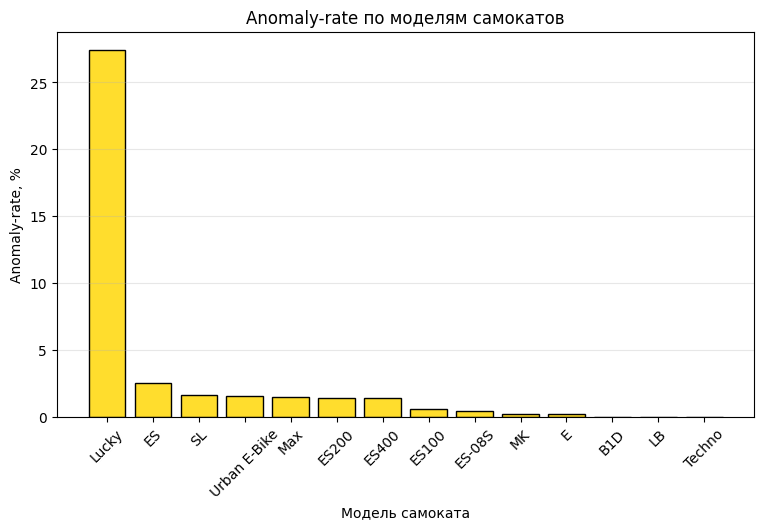

In [420]:
anomaly_by_model = df.groupby("transport_model")["rule_anomaly"].mean() * 100
anomaly_by_model = anomaly_by_model.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(anomaly_by_model.index, anomaly_by_model.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("Модель самоката")
plt.ylabel("Anomaly-rate, %")
plt.title("Anomaly-rate по моделям самокатов")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [422]:
df["anomaly_group"] = "Норма"
df.loc[df["rule_anomaly"] == 1, "anomaly_group"] = "Аномалия"

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


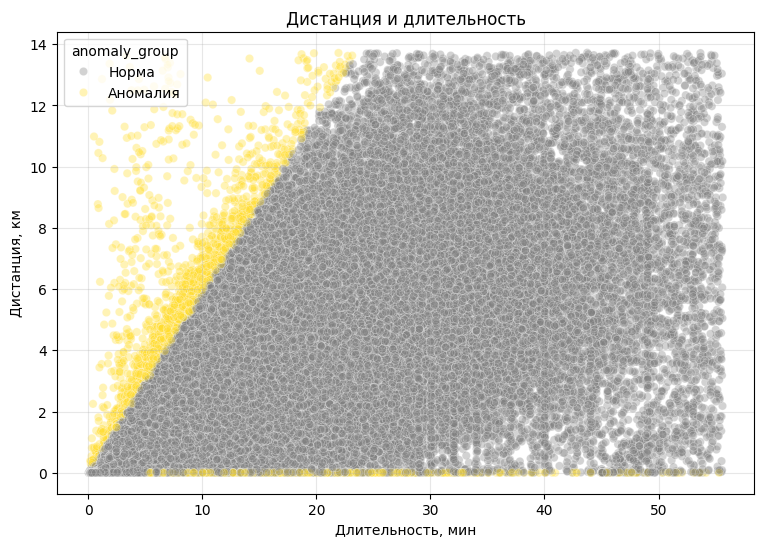

In [424]:
scatter_df = df[df["distance_km"] <= df["distance_km"].quantile(0.99)]
scatter_df = scatter_df[scatter_df["duration_min"] <= scatter_df["duration_min"].quantile(0.99)]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x="duration_min", y="distance_km", hue="anomaly_group", palette={"Норма": "gray", "Аномалия": "#FFDD2D"}, alpha=0.35)
plt.xlabel("Длительность, мин")
plt.ylabel("Дистанция, км")
plt.title("Дистанция и длительность")
plt.grid(alpha=0.3)
plt.show()

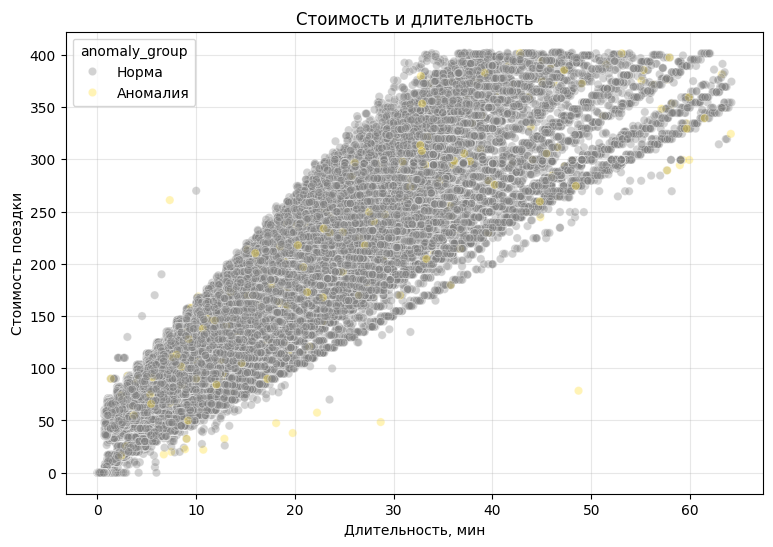

In [425]:
scatter_df = df[df["duration_min"] <= df["duration_min"].quantile(0.99)]
scatter_df = scatter_df[scatter_df["nominal_price_rub_amt"] <= scatter_df["nominal_price_rub_amt"].quantile(0.99)]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x="duration_min", y="nominal_price_rub_amt", hue="anomaly_group", palette={"Норма": "gray", "Аномалия": "#FFDD2D"}, alpha=0.35)
plt.xlabel("Длительность, мин")
plt.ylabel("Стоимость поездки")
plt.title("Стоимость и длительность")
plt.grid(alpha=0.3)
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


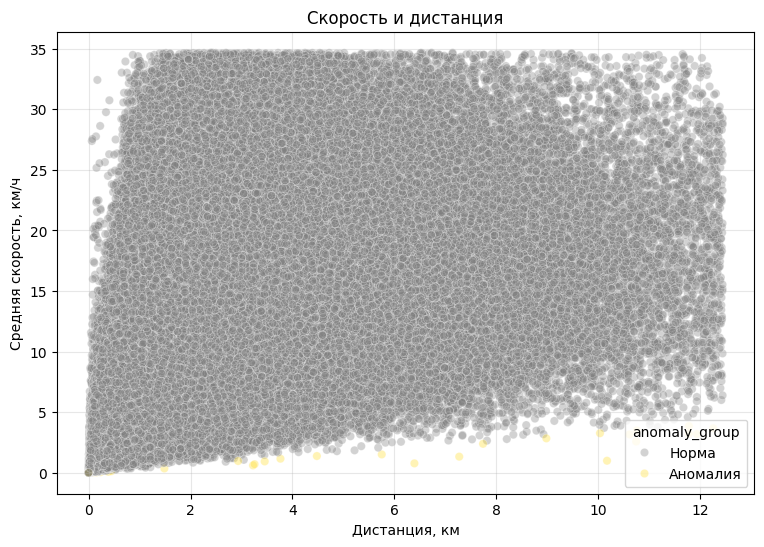

In [474]:
scatter_df = df[df["avg_speed_kmh"] <= df["avg_speed_kmh"].quantile(0.99)]
scatter_df = scatter_df[scatter_df["distance_km"] <= scatter_df["distance_km"].quantile(0.99)]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x="distance_km", y="avg_speed_kmh", hue="anomaly_group", palette={"Норма": "gray", "Аномалия": "#FFDD2D"}, alpha=0.35)
plt.xlabel("Дистанция, км")
plt.ylabel("Средняя скорость, км/ч")
plt.title("Скорость и дистанция")
plt.grid(alpha=0.3)
plt.show()

## RFM и клиентские уровни

In [430]:
def make_rfm(g):
    return pd.Series({
        "freq": len(g),
        "monetary_sum": g["nominal_price_rub_amt"].sum(),
        "monetary_mean": g["nominal_price_rub_amt"].mean(),
        "dist_mean": g["distance_km"].mean(),
        "dur_mean": g["duration_min"].mean(),
        "recency_days": (pd.Timestamp("2024-09-01") - g["book_start_dttm"].max()).days,
        "tenure_days": (g["book_start_dttm"].max() - g["book_start_dttm"].min()).days,
        "active_days": g["book_start_dttm"].dt.normalize().nunique(),
        "avg_hour": g["book_start_dttm"].dt.hour.mean(),
        "weekend_share": (g["book_start_dttm"].dt.dayofweek >= 5).mean(),
        "minute_cost_mean": g["minute_cost"].mean(),
        "n_transport": g["transport_model"].nunique(),
        "age": g["age"].iloc[0],
        "gender_cd": g["gender_cd"].iloc[0],
    })

In [431]:
rfm = df.groupby("party_rk").apply(make_rfm).reset_index()

/tmp/ipykernel_1568/1362099622.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rfm = df.groupby("party_rk").apply(make_rfm).reset_index()


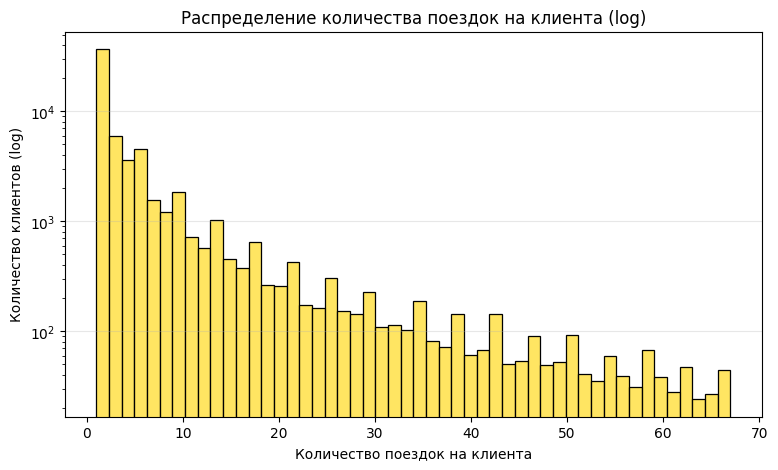

In [438]:
freq_limit = rfm["freq"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=rfm[rfm["freq"] <= freq_limit], x="freq", bins=50, color="#FFDD2D", edgecolor="black")
plt.yscale("log")
plt.xlabel("Количество поездок на клиента")
plt.ylabel("Количество клиентов (log)")
plt.title("Распределение количества поездок на клиента (log)")
plt.grid(axis="y", alpha=0.3)
plt.show()

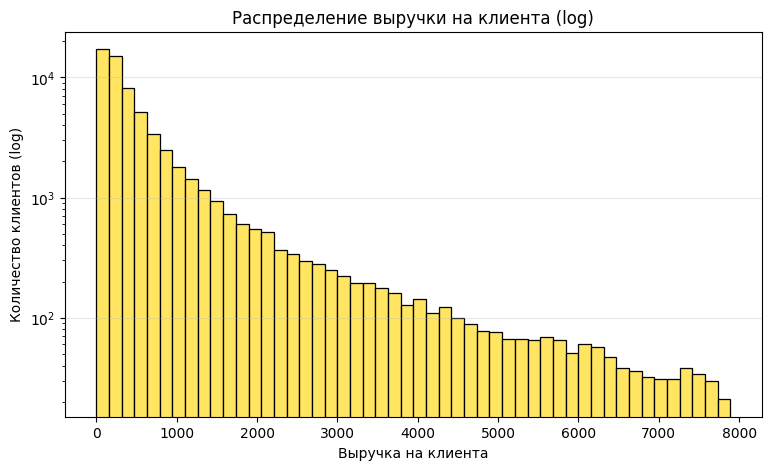

In [439]:
monetary_limit = rfm["monetary_sum"].quantile(0.99)

plt.figure(figsize=(9, 5))
sns.histplot(data=rfm[rfm["monetary_sum"] <= monetary_limit], x="monetary_sum", bins=50, color="#FFDD2D", edgecolor="black")
plt.yscale("log")
plt.xlabel("Выручка на клиента")
plt.ylabel("Количество клиентов (log)")
plt.title("Распределение выручки на клиента (log)")
plt.grid(axis="y", alpha=0.3)
plt.show()

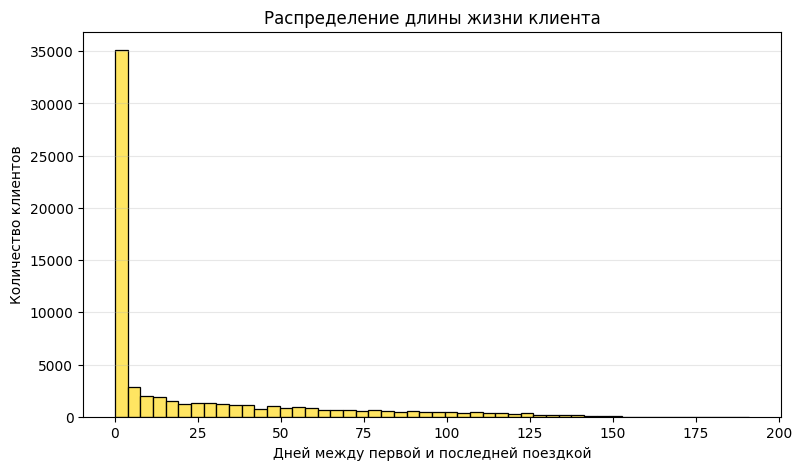

In [444]:
plt.figure(figsize=(9, 5))
sns.histplot(data=rfm, x="tenure_days", bins=50, color="#FFDD2D", edgecolor="black")
plt.xlabel("Дней между первой и последней поездкой")
plt.ylabel("Количество клиентов")
plt.title("Распределение длины жизни клиента")
plt.grid(axis="y", alpha=0.3)
plt.show()

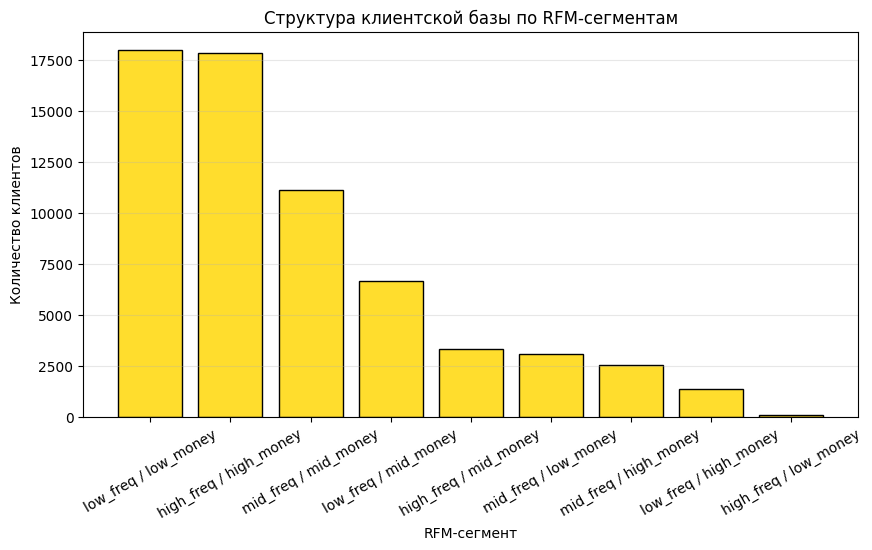

In [448]:
freq_33 = rfm["freq"].quantile(0.33)
freq_66 = rfm["freq"].quantile(0.66)

money_33 = rfm["monetary_sum"].quantile(0.33)
money_66 = rfm["monetary_sum"].quantile(0.66)

rfm["freq_segment"] = "low_freq"
rfm.loc[rfm["freq"] > freq_33, "freq_segment"] = "mid_freq"
rfm.loc[rfm["freq"] > freq_66, "freq_segment"] = "high_freq"

rfm["money_segment"] = "low_money"
rfm.loc[rfm["monetary_sum"] > money_33, "money_segment"] = "mid_money"
rfm.loc[rfm["monetary_sum"] > money_66, "money_segment"] = "high_money"

rfm["rfm_segment"] = rfm["freq_segment"] + " / " + rfm["money_segment"]

rfm_segments = rfm["rfm_segment"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(rfm_segments.index, rfm_segments.values, color="#FFDD2D", edgecolor="black")
plt.xlabel("RFM-сегмент")
plt.ylabel("Количество клиентов")
plt.title("Структура клиентской базы по RFM-сегментам")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [456]:
df["ride_month_period"] = df["book_start_dttm"].dt.to_period("M")
df["cohort_month"] = df.groupby("party_rk")["ride_month_period"].transform("min")

cohort_data = df.groupby(["cohort_month", "ride_month_period"])["party_rk"].nunique().reset_index()

cohort_data["cohort_index"] = (
    (cohort_data["ride_month_period"].dt.year - cohort_data["cohort_month"].dt.year) * 12 +
    (cohort_data["ride_month_period"].dt.month - cohort_data["cohort_month"].dt.month)
)

cohort_counts = cohort_data.pivot_table(index="cohort_month", columns="cohort_index", values="party_rk")

retention = cohort_counts.div(cohort_counts[0], axis=0) * 100

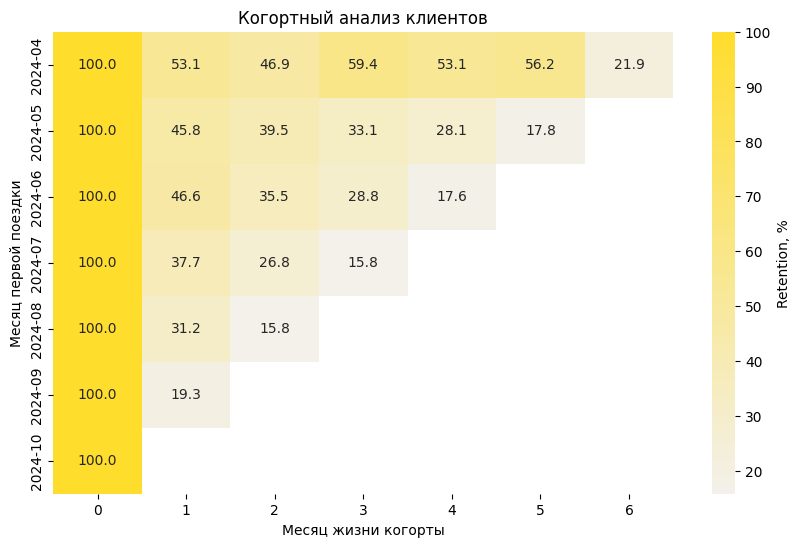

In [458]:
plt.figure(figsize=(10, 6))
sns.heatmap(retention, annot=True, fmt=".1f", cmap=sns.light_palette("#FFDD2D", as_cmap=True), cbar_kws={"label": "Retention, %"})
plt.xlabel("Месяц жизни когорты")
plt.ylabel("Месяц первой поездки")
plt.title("Когортный анализ клиентов")
plt.show()

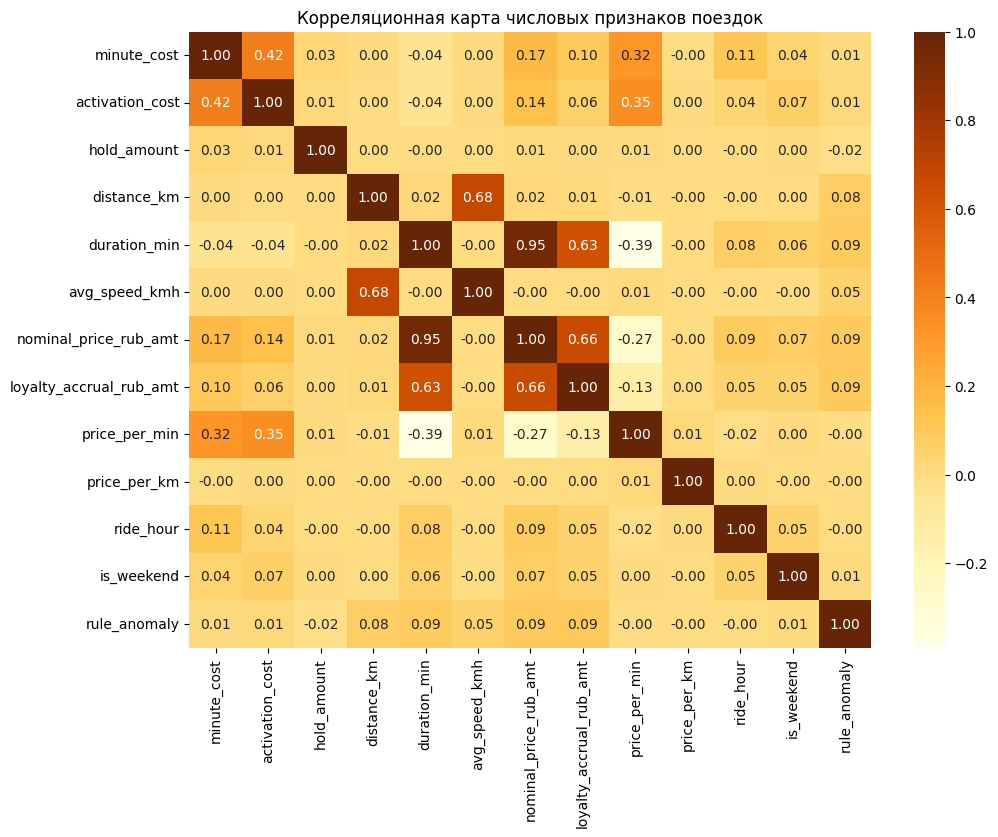

In [473]:
trip_num_cols = ["minute_cost", "activation_cost", "hold_amount", "distance_km", "duration_min", "avg_speed_kmh", "nominal_price_rub_amt", "loyalty_accrual_rub_amt", "price_per_min", "price_per_km", "ride_hour", "is_weekend", "rule_anomaly"]

corr = df[trip_num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrBr")
plt.title("Корреляционная карта числовых признаков поездок")
plt.show()

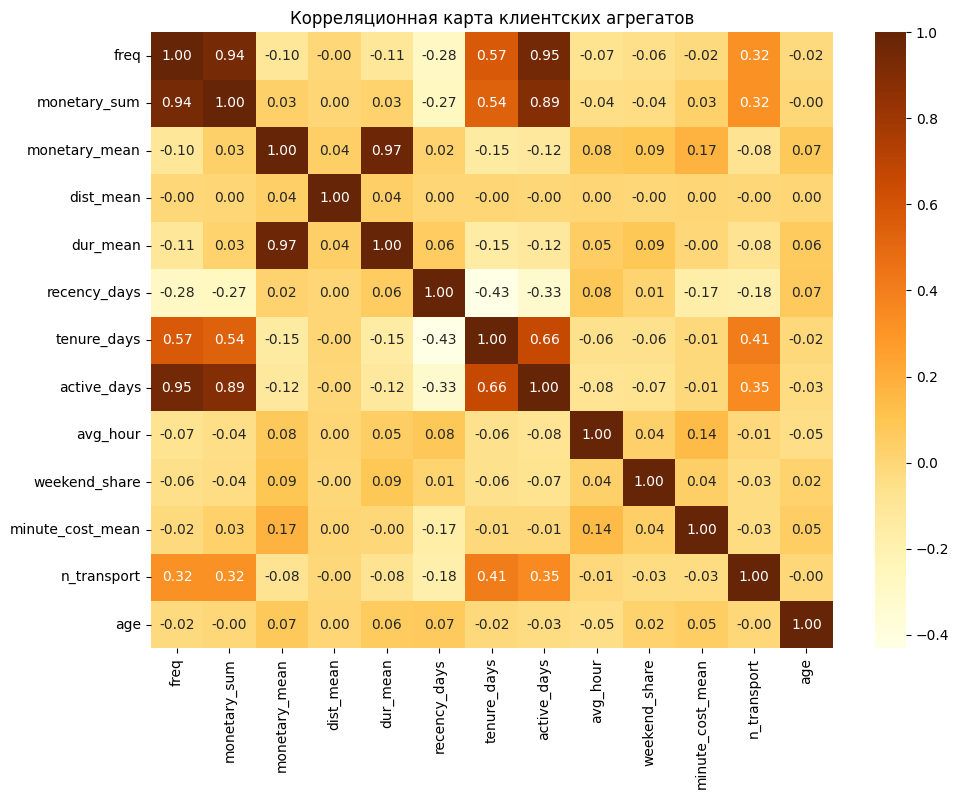

In [472]:
client_num_cols = ["freq", "monetary_sum", "monetary_mean", "dist_mean", "dur_mean", "recency_days", "tenure_days", "active_days", "avg_hour", "weekend_share", "minute_cost_mean", "n_transport", "age"]

client_num_cols = [col for col in client_num_cols if col in rfm.columns]
corr = rfm[client_num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrBr")
plt.title("Корреляционная карта клиентских агрегатов")
plt.show()